#Stock Market

##Data Prep

In [ ]:
!pip install pykalman

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 248.5/248.5 kB 5.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 141.5/141.5 kB 13.9 MB/s eta 0:00:00


In [ ]:
import yfinance as yf

# Define the stock ticker
ticker = "AAPL"

# Download historical data (e.g., last 5 years)
apple_stock = yf.download(ticker, start="2020-01-01", end="2025-02-24")

# Display the first few rows
print(apple_stock.head())

# Save to CSV if needed
apple_stock.to_csv("apple_stock_data.csv")


YF.download() has changed argument auto_adjust default to True


[*********************100%***********************]  1 of 1 completed

Price           Close       High        Low       Open     Volume
Ticker           AAPL       AAPL       AAPL       AAPL       AAPL
Date                                                             
2020-01-02  72.716072  72.776598  71.466812  71.721019  135480400
2020-01-03  72.009132  72.771760  71.783977  71.941343  146322800
2020-01-06  72.582924  72.621661  70.876090  71.127881  118387200
2020-01-07  72.241554  72.849231  72.021238  72.592601  108872000
2020-01-08  73.403656  73.706287  71.943766  71.943766  132079200


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from sklearn.preprocessing import MinMaxScaler

In [ ]:
df = pd.read_csv("apple_stock_data.csv", skiprows=2,  parse_dates=True)

print(df.head())

         Date  Unnamed: 1  Unnamed: 2  Unnamed: 3  Unnamed: 4  Unnamed: 5
0  2020-01-02   72.716072   72.776598   71.466812   71.721019   135480400
1  2020-01-03   72.009132   72.771760   71.783977   71.941343   146322800
2  2020-01-06   72.582924   72.621661   70.876090   71.127881   118387200
3  2020-01-07   72.241554   72.849231   72.021238   72.592601   108872000
4  2020-01-08   73.403656   73.706287   71.943766   71.943766   132079200


In [ ]:
df.columns = ["Date","Close", "High", "Low", "Open", "Volume"]
df = df.astype({"Date":str,"Close": float, "High": float, "Low": float, "Open": float, "Volume": int})

print(df.head())

         Date      Close       High        Low       Open     Volume
0  2020-01-02  72.716072  72.776598  71.466812  71.721019  135480400
1  2020-01-03  72.009132  72.771760  71.783977  71.941343  146322800
2  2020-01-06  72.582924  72.621661  70.876090  71.127881  118387200
3  2020-01-07  72.241554  72.849231  72.021238  72.592601  108872000
4  2020-01-08  73.403656  73.706287  71.943766  71.943766  132079200


In [ ]:
df

,Date,Close,High,Low,Open,Volume
0,2020-01-02,72.716072,72.776598,71.466812,71.721019,135480400
1,2020-01-03,72.009132,72.771760,71.783977,71.941343,146322800
2,2020-01-06,72.582924,72.621661,70.876090,71.127881,118387200
3,2020-01-07,72.241554,72.849231,72.021238,72.592601,108872000
4,2020-01-08,73.403656,73.706287,71.943766,71.943766,132079200
...,...,...,...,...,...,...
1287,2025-02-14,244.600006,245.550003,240.990005,241.250000,40896200
1288,2025-02-18,244.470001,245.179993,241.839996,244.149994,48822500
1289,2025-02-19,244.869995,246.009995,243.160004,244.660004,32204200
1290,2025-02-20,245.830002,246.779999,244.289993,244.940002,32316900


In [ ]:
# Check the column names
print(df.columns)

# Summary statistics
print(df.describe())

# Check for missing values
print(df.isnull().sum())

Index(['Date', 'Close', 'High', 'Low', 'Open', 'Volume'], dtype='object')
             Close         High          Low         Open        Volume
count  1292.000000  1292.000000  1292.000000  1292.000000  1.292000e+03
mean    154.367569   155.922365   152.631020   154.207761  8.959961e+07
std      43.617778    43.796479    43.351643    43.558227  5.296492e+07
min      54.449886    55.452152    51.595983    55.350227  2.323470e+07
25%     127.874533   128.848320   125.851276   127.612479  5.461315e+07
50%     152.266258   153.980780   150.099002   152.054921  7.546680e+07
75%     179.826771   181.557453   177.848024   179.765435  1.062408e+08
max     258.735504   259.814335   257.347047   257.906429  4.265100e+08
Date      0
Close     0
High      0
Low       0
Open      0
Volume    0
dtype: int64


In [ ]:
df['Date'] = pd.to_datetime(df['Date'])


In [ ]:
df.to_csv("output.csv", index=False)


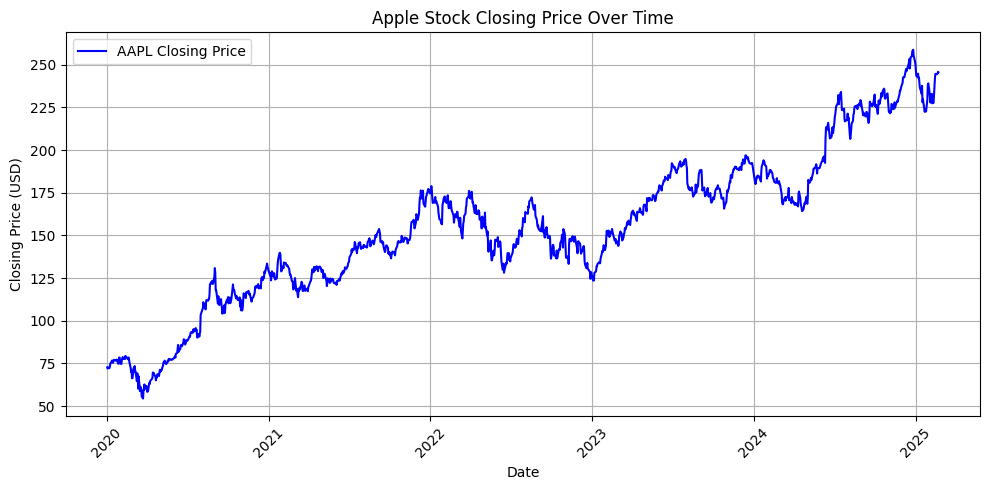

In [ ]:
import matplotlib.pyplot as plt

# Plot the closing price over time
plt.figure(figsize=(10, 5))
plt.plot(df['Date'], df["Close"], label="AAPL Closing Price", color="blue")
plt.xlabel("Date")
plt.ylabel("Closing Price (USD)")
plt.title("Apple Stock Closing Price Over Time")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


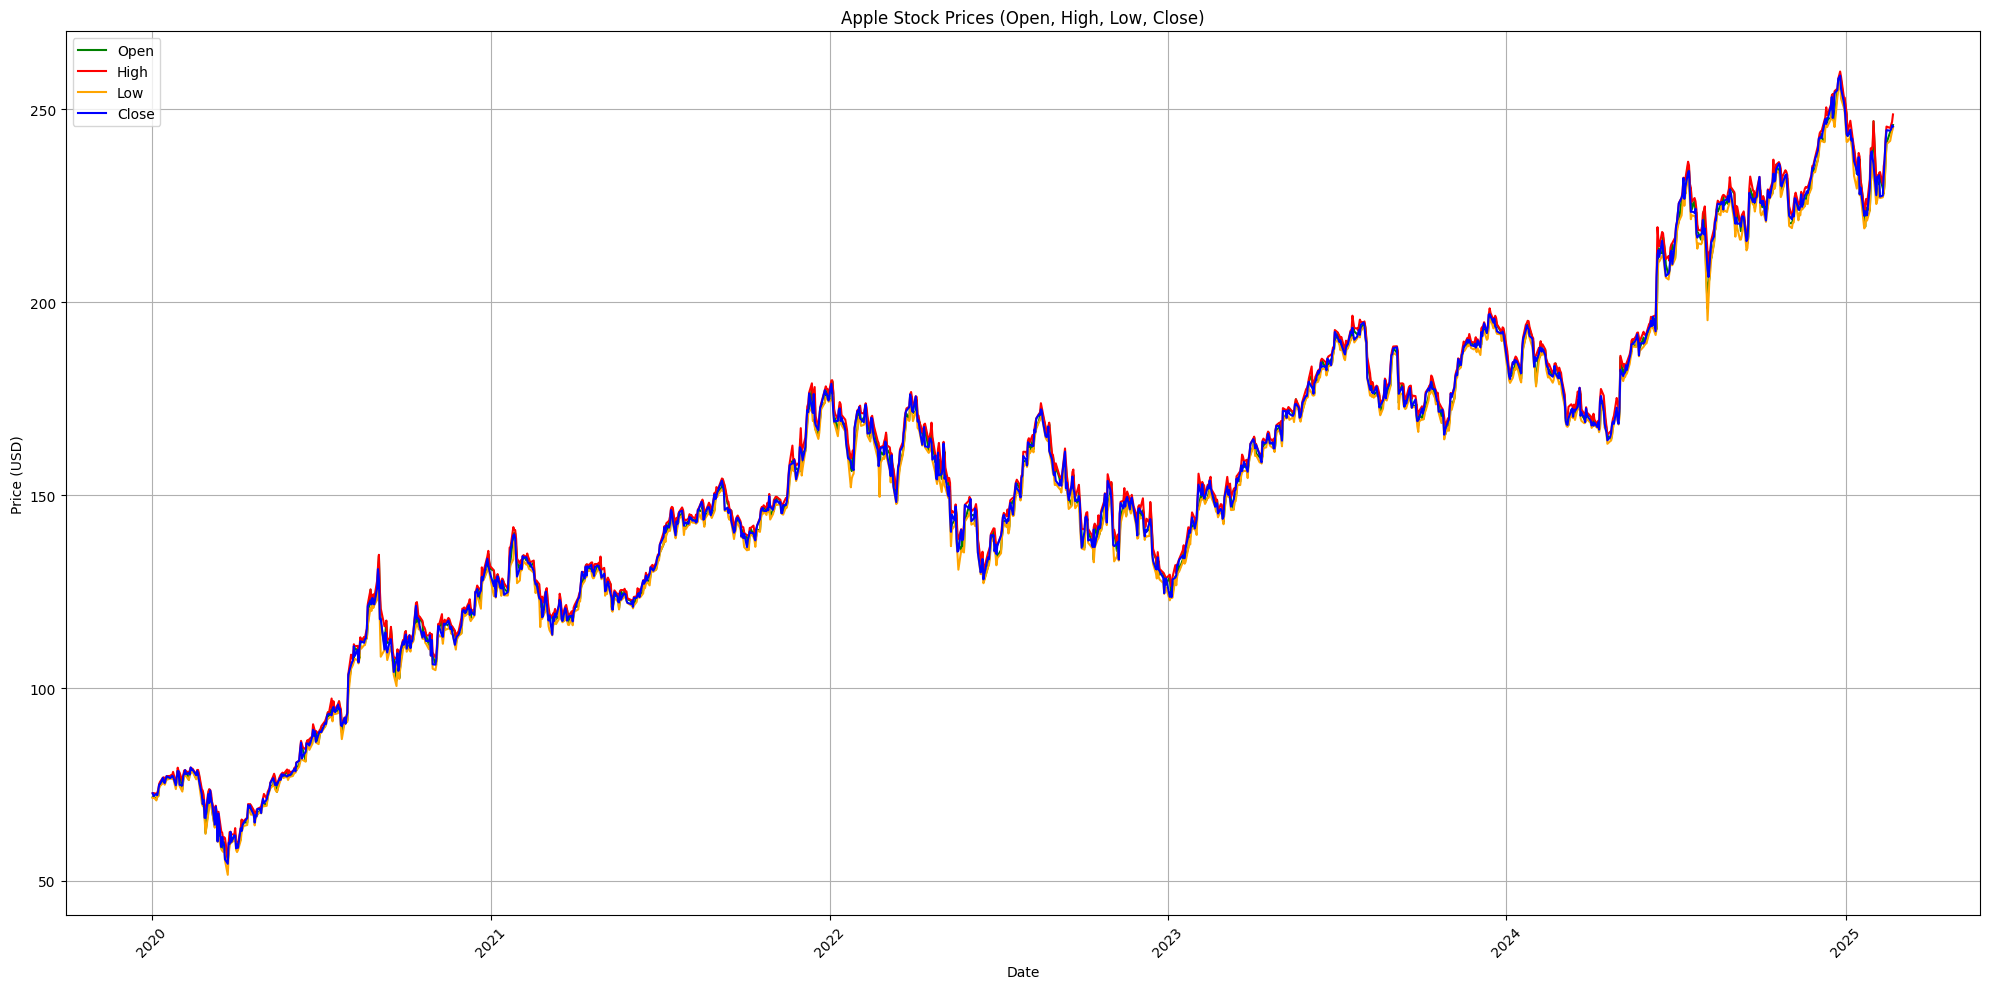

In [ ]:
# Plot Open, High, Low, and Close prices
plt.figure(figsize=(20, 10))
plt.plot(df['Date'], df["Open"], label="Open", color="green")
plt.plot(df['Date'], df["High"], label="High", color="red")
plt.plot(df['Date'], df["Low"], label="Low", color="orange")
plt.plot(df['Date'], df["Close"], label="Close", color="blue")

plt.xlabel("Date")
plt.ylabel("Price (USD)")
plt.title("Apple Stock Prices (Open, High, Low, Close)")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


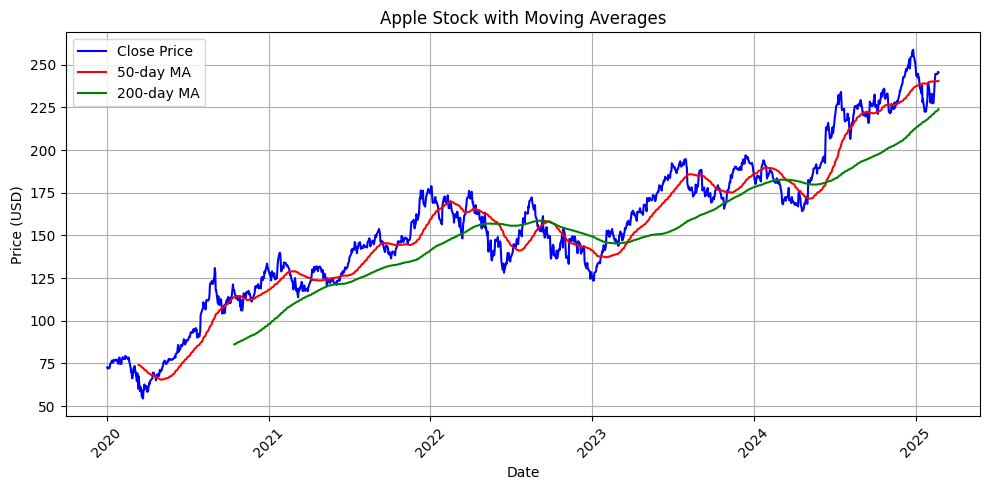

In [ ]:
# Calculate moving averages
df["50-day MA"] = df["Close"].rolling(window=50).mean()
df["200-day MA"] = df["Close"].rolling(window=200).mean()

# Plot the Closing Price and Moving Averages
plt.figure(figsize=(10, 5))
plt.plot(df['Date'], df["Close"], label="Close Price", color="blue")
plt.plot(df['Date'], df["50-day MA"], label="50-day MA", color="red")
plt.plot(df['Date'], df["200-day MA"], label="200-day MA", color="green")

plt.xlabel("Date")
plt.ylabel("Price (USD)")
plt.title("Apple Stock with Moving Averages")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


##Model 1

###Body

In [ ]:
data = df[['Date', 'Close']]
data

,Date,Close
0,2020-01-02,72.716072
1,2020-01-03,72.009117
2,2020-01-06,72.582901
3,2020-01-07,72.241562
4,2020-01-08,73.403656
...,...,...
1287,2025-02-14,244.600006
1288,2025-02-18,244.470001
1289,2025-02-19,244.869995
1290,2025-02-20,245.830002


In [ ]:
device = 'cuda:0' if torch.cuda.is_available() else 'cpu'
device

'cuda:0'

<ipython-input-48-27440ea654b2>:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data['Date'] = pd.to_datetime(data['Date'])


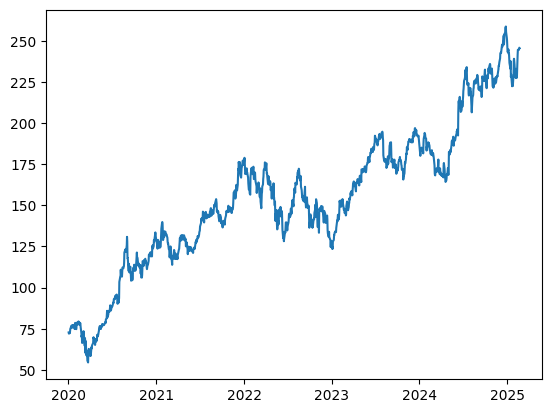

In [ ]:
data['Date'] = pd.to_datetime(data['Date'])

plt.plot(data['Date'], data['Close'])

In [ ]:
from copy import deepcopy as dc

def prepare_dataframe_for_lstm(df, n_steps):
    df = dc(df)

    df.set_index('Date', inplace=True)

    for i in range(1, n_steps+1):
        df[f'Close(t-{i})'] = df['Close'].shift(i)

    df.dropna(inplace=True)

    return df

lookback = 7
shifted_df = prepare_dataframe_for_lstm(data, lookback)
shifted_df

,Close,Close(t-1),Close(t-2),Close(t-3),Close(t-4),Close(t-5),Close(t-6),Close(t-7)
Date,,,,,,,,
2020-01-13,76.737434,75.132263,74.962791,73.403656,72.241562,72.582901,72.009117,72.716072
2020-01-14,75.701202,76.737434,75.132263,74.962791,73.403656,72.241562,72.582901,72.009117
2020-01-15,75.376801,75.701202,76.737434,75.132263,74.962791,73.403656,72.241562,72.582901
2020-01-16,76.321007,75.376801,75.701202,76.737434,75.132263,74.962791,73.403656,72.241562
2020-01-17,77.165955,76.321007,75.376801,75.701202,76.737434,75.132263,74.962791,73.403656
...,...,...,...,...,...,...,...,...
2025-02-14,244.600006,241.529999,236.869995,232.619995,227.649994,227.380005,232.963867,232.214691
2025-02-18,244.470001,244.600006,241.529999,236.869995,232.619995,227.649994,227.380005,232.963867
2025-02-19,244.869995,244.470001,244.600006,241.529999,236.869995,232.619995,227.649994,227.380005


In [ ]:
shifted_df_as_np = shifted_df.to_numpy()

shifted_df_as_np

array([[ 76.73743439,  75.13226318,  74.96279144, ...,  72.582901  ,
         72.00911713,  72.71607208],
       [ 75.70120239,  76.73743439,  75.13226318, ...,  72.24156189,
         72.582901  ,  72.00911713],
       [ 75.37680054,  75.70120239,  76.73743439, ...,  73.40365601,
         72.24156189,  72.582901  ],
       ...,
       [244.86999512, 244.47000122, 244.6000061 , ..., 232.61999512,
        227.6499939 , 227.38000488],
       [245.83000183, 244.86999512, 244.47000122, ..., 236.86999512,
        232.61999512, 227.6499939 ],
       [245.55000305, 245.83000183, 244.86999512, ..., 241.52999878,
        236.86999512, 232.61999512]])

In [ ]:
scaler = MinMaxScaler(feature_range=(-1,1))
shifted_df_as_np = scaler.fit_transform(shifted_df_as_np)
shifted_df_as_np

array([[-0.78180019, -0.79751516, -0.79917433, ..., -0.82247397,
        -0.82809143, -0.82117019],
       [-0.79194513, -0.78180019, -0.79751516, ..., -0.82581575,
        -0.82247397, -0.82809143],
       [-0.79512109, -0.79194513, -0.78180019, ..., -0.8144386 ,
        -0.82581575, -0.82247397],
       ...,
       [ 0.86425369,  0.86033766,  0.86161044, ...,  0.74432356,
         0.69566618,  0.69302293],
       [ 0.87365236,  0.86425369,  0.86033766, ...,  0.78593197,
         0.74432356,  0.69566618],
       [ 0.87091111,  0.87365236,  0.86425369, ...,  0.83155441,
         0.78593197,  0.74432356]])

In [ ]:
X = shifted_df_as_np[:, 1:]
Y = shifted_df_as_np[:, 0]

X.shape,Y.shape

((1285, 7), (1285,))

In [ ]:
X = dc(np.flip(X, axis = 1))
X

array([[-0.82117019, -0.82809143, -0.82247397, ..., -0.8144386 ,
        -0.79917433, -0.79751516],
       [-0.82809143, -0.82247397, -0.82581575, ..., -0.79917433,
        -0.79751516, -0.78180019],
       [-0.82247397, -0.82581575, -0.8144386 , ..., -0.79751516,
        -0.78180019, -0.79194513],
       ...,
       [ 0.69302293,  0.69566618,  0.74432356, ...,  0.83155441,
         0.86161044,  0.86033766],
       [ 0.69566618,  0.74432356,  0.78593197, ...,  0.86161044,
         0.86033766,  0.86425369],
       [ 0.74432356,  0.78593197,  0.83155441, ...,  0.86033766,
         0.86425369,  0.87365236]])

In [ ]:
split_index =   int(len(X) * 0.95)
split_index

1220

In [ ]:
X_train = X[:split_index]
X_test = X[split_index:]

y_train = Y[:split_index]
y_test = Y[split_index:]

X_train.shape,X_test.shape,y_train.shape,y_test.shape

((1220, 7), (65, 7), (1220,), (65,))

In [ ]:
X_train = X_train.reshape((-1, lookback, 1))
X_test = X_test.reshape((-1, lookback, 1))

y_train = y_train.reshape((-1, 1))
y_test = y_test.reshape((-1, 1))

X_train.shape, X_test.shape, y_train.shape, y_test.shape

((1220, 7, 1), (65, 7, 1), (1220, 1), (65, 1))

In [ ]:
X_train = torch.tensor(X_train).float()
y_train = torch.tensor(y_train).float()
X_test = torch.tensor(X_test).float()
y_test = torch.tensor(y_test).float()

X_train.shape, X_test.shape, y_train.shape, y_test.shape

(torch.Size([1220, 7, 1]),
 torch.Size([65, 7, 1]),
 torch.Size([1220, 1]),
 torch.Size([65, 1]))

In [ ]:
from torch.utils.data import Dataset

class TimeSeriesDataset(Dataset):
    def __init__(self, X, y):
        self.X = X
        self.y = y

    def __len__(self):
        return len(self.X)

    def __getitem__(self, i):
        return self.X[i], self.y[i]

train_dataset = TimeSeriesDataset(X_train, y_train)
test_dataset = TimeSeriesDataset(X_test, y_test)

In [ ]:
train_dataset

In [ ]:
from torch.utils.data import DataLoader

batch_size = 16

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

In [ ]:
for _, batch in enumerate(train_loader):
    x_batch, y_batch = batch[0].to(device), batch[1].to(device)
    print(x_batch.shape, y_batch.shape)
    break

torch.Size([16, 7, 1]) torch.Size([16, 1])


In [ ]:
class LSTM(nn.Module):
    def __init__(self, input_size, hidden_size, num_stacked_layers):
        super().__init__()
        self.hidden_size = hidden_size
        self.num_stacked_layers = num_stacked_layers

        self.lstm = nn.LSTM(input_size, hidden_size, num_stacked_layers,
                            batch_first=True)

        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        batch_size = x.size(0)
        h0 = torch.zeros(self.num_stacked_layers, batch_size, self.hidden_size).to(device)
        c0 = torch.zeros(self.num_stacked_layers, batch_size, self.hidden_size).to(device)

        out, _ = self.lstm(x, (h0, c0))
        out = self.fc(out[:, -1, :])
        return out

model = LSTM(1, 4, 1)
model.to(device)
model

LSTM(
  (lstm): LSTM(1, 4, batch_first=True)
  (fc): Linear(in_features=4, out_features=1, bias=True)
)

In [ ]:
def train_one_epoch():
    model.train(True)
    print(f'Epoch: {epoch + 1}')
    running_loss = 0.0

    for batch_index, batch in enumerate(train_loader):
        x_batch, y_batch = batch[0].to(device), batch[1].to(device)

        output = model(x_batch)
        loss = loss_function(output, y_batch)
        running_loss += loss.item()

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        if batch_index % 100 == 99:  # print every 100 batches
            avg_loss_across_batches = running_loss / 100
            print('Batch {0}, Loss: {1:.3f}'.format(batch_index+1,
                                                    avg_loss_across_batches))
            running_loss = 0.0
    print()

def validate_one_epoch():
    model.train(False)
    running_loss = 0.0

    for batch_index, batch in enumerate(test_loader):
        x_batch, y_batch = batch[0].to(device), batch[1].to(device)

        with torch.no_grad():
            output = model(x_batch)
            loss = loss_function(output, y_batch)
            running_loss += loss.item()

    avg_loss_across_batches = running_loss / len(test_loader)

    print('Val Loss: {0:.3f}'.format(avg_loss_across_batches))
    print('***************************************************')
    print()

In [ ]:
learning_rate = 0.0005
num_epochs = 100
loss_function = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

for epoch in range(num_epochs):
    train_one_epoch()
    validate_one_epoch()

Epoch: 1

Val Loss: 1.070
***************************************************

Epoch: 2

Val Loss: 0.882
***************************************************

Epoch: 3

Val Loss: 0.733
***************************************************

Epoch: 4

Val Loss: 0.618
***************************************************

Epoch: 5

Val Loss: 0.506
***************************************************

Epoch: 6

Val Loss: 0.374
***************************************************

Epoch: 7

Val Loss: 0.257
***************************************************

Epoch: 8

Val Loss: 0.190
***************************************************

Epoch: 9

Val Loss: 0.156
***************************************************

Epoch: 10

Val Loss: 0.136
***************************************************

Epoch: 11

Val Loss: 0.120
***************************************************

Epoch: 12

Val Loss: 0.106
***************************************************

Epoch: 13

Val Loss: 0.093
**********************

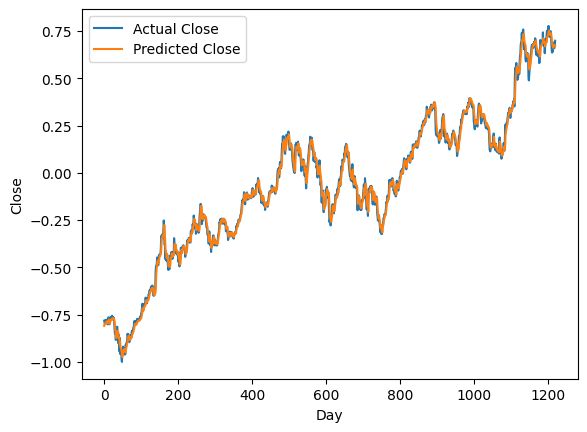

In [ ]:
with torch.no_grad():
    predicted = model(X_train.to(device)).to('cpu').numpy()

plt.plot(y_train, label='Actual Close')
plt.plot(predicted, label='Predicted Close')
plt.xlabel('Day')
plt.ylabel('Close')
plt.legend()
plt.show()


In [ ]:
train_predictions = predicted.flatten()

dummies = np.zeros((X_train.shape[0], lookback+1))
dummies[:, 0] = train_predictions
dummies = scaler.inverse_transform(dummies)

train_predictions = dc(dummies[:, 0])
train_predictions

array([ 73.9647145 ,  75.06715707,  75.13002367, ..., 225.09349332,
       225.00623135, 225.35140104])

In [ ]:
dummies = np.zeros((X_train.shape[0], lookback+1))
dummies[:, 0] = y_train.flatten()
dummies = scaler.inverse_transform(dummies)

new_y_train = dc(dummies[:, 0])
new_y_train

array([ 76.73743253,  75.70120507,  75.37680219, ..., 223.98373276,
       224.87275397, 227.96935738])

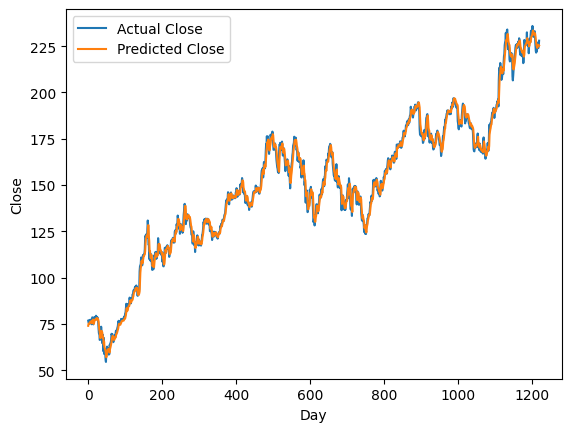

In [ ]:
plt.plot(new_y_train, label='Actual Close')
plt.plot(train_predictions, label='Predicted Close')
plt.xlabel('Day')
plt.ylabel('Close')
plt.legend()
plt.show()


In [ ]:
test_predictions = model(X_test.to(device)).detach().cpu().numpy().flatten()

dummies = np.zeros((X_test.shape[0], lookback+1))
dummies[:, 0] = test_predictions
dummies = scaler.inverse_transform(dummies)

test_predictions = dc(dummies[:, 0])
test_predictions

array([226.65519207, 225.96740366, 226.89047001, 227.34397895,
       227.94857231, 228.11835355, 228.77991406, 230.15152748,
       231.63292307, 232.31942688, 233.64848389, 235.10875956,
       236.91127041, 237.9558813 , 238.59855017, 238.96077287,
       240.4475017 , 241.39571226, 241.52280314, 242.11316232,
       242.46314776, 243.51762151, 244.68027014, 243.70739025,
       243.94198022, 245.31973662, 246.06372508, 247.23142691,
       247.98911378, 247.55635337, 246.69029679, 245.87175241,
       243.5366897 , 242.2685937 , 241.88576859, 240.57293659,
       240.06084104, 237.84288458, 236.01779265, 234.71589503,
       235.47350276, 232.11422459, 231.34236441, 227.89260971,
       226.79300424, 225.8726654 , 224.84342718, 226.85788604,
       230.72457796, 232.82789388, 233.71121047, 233.9829749 ,
       231.54952102, 232.43359254, 232.30810286, 232.28059644,
       230.11149158, 229.30714485, 230.63125216, 232.65810656,
       235.06616662, 237.26940184, 238.46761157, 239.54

In [ ]:
dummies = np.zeros((X_test.shape[0], lookback+1))
dummies[:, 0] = y_test.flatten()
dummies = scaler.inverse_transform(dummies)

new_y_test = dc(dummies[:, 0])
new_y_test

array([224.75288369, 227.76957966, 228.02928339, 228.74848685,
       228.26903005, 229.61753881, 232.61424118, 234.80183586,
       234.67198095, 237.06935015, 239.32686155, 242.38350211,
       242.7431008 , 242.77307293, 242.57328912, 246.47900631,
       247.49787635, 246.21928431, 247.68768162, 247.85748112,
       250.76427925, 253.20159913, 247.77757369, 249.51565327,
       254.2105089 , 254.98965663, 257.91644228, 258.73550415,
       255.30929855, 251.92301927, 250.14497075, 243.58219889,
       243.09272703, 244.73092384, 241.94400208, 242.4334435 ,
       236.58987509, 234.14256451, 233.02378734, 237.60875122,
       228.00930805, 229.72741839, 222.39547733, 223.58416513,
       223.41436564, 222.53532296, 229.60754201, 237.99832204,
       239.09712387, 237.32905389, 235.74081673, 227.75958286,
       232.54432446, 232.21469183, 232.96386742, 227.38000275,
       227.64999552, 232.61999452, 236.86999251, 241.52999937,
       244.6000035 , 244.47000247, 244.86999626, 245.82

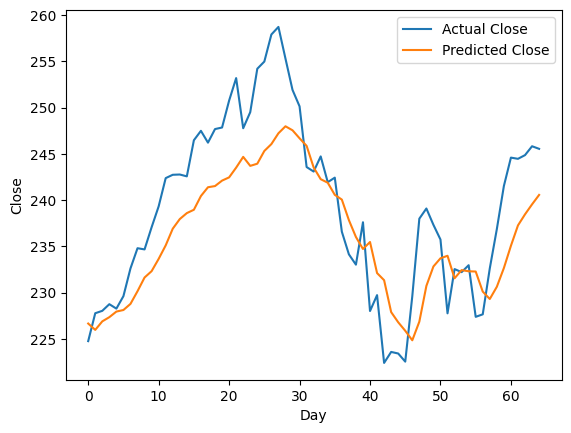

In [ ]:
plt.plot(new_y_test, label='Actual Close')
plt.plot(test_predictions, label='Predicted Close')
plt.xlabel('Day')
plt.ylabel('Close')
plt.legend()
plt.show()


##Model 2

In [ ]:
data2 = df[['Date', 'Close']]
data2

,Date,Close
0,2020-01-02,72.716072
1,2020-01-03,72.009117
2,2020-01-06,72.582901
3,2020-01-07,72.241562
4,2020-01-08,73.403656
...,...,...
1287,2025-02-14,244.600006
1288,2025-02-18,244.470001
1289,2025-02-19,244.869995
1290,2025-02-20,245.830002


In [ ]:
device = 'cuda:0' if torch.cuda.is_available() else 'cpu'
device

'cuda:0'

In [ ]:
import datetime

def str_to_datetime(s):
    split = s.split('-')
    year,month,day = int(split[0]),int(split[1]),int(split[2])
    return datetime.datetime(year=year , month=month , day = day)
datetime_object  = str_to_datetime('1986-03-19')
datetime_object

datetime.datetime(1986, 3, 19, 0, 0)

In [ ]:
data2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1292 entries, 0 to 1291
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Date    1292 non-null   datetime64[ns]
 1   Close   1292 non-null   float64       
dtypes: datetime64[ns](1), float64(1)
memory usage: 20.3 KB


In [ ]:
data2.index = data2.pop('Date')

In [ ]:
data2

,Close
Date,
2020-01-02,72.716072
2020-01-03,72.009117
2020-01-06,72.582901
2020-01-07,72.241562
2020-01-08,73.403656
...,...
2025-02-14,244.600006
2025-02-18,244.470001
2025-02-19,244.869995


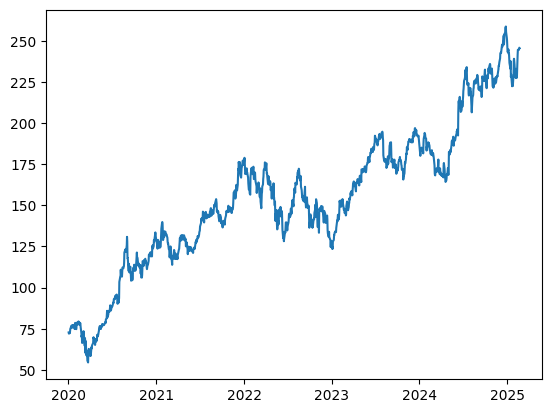

In [ ]:
plt.plot(data2.index,data2["Close"])

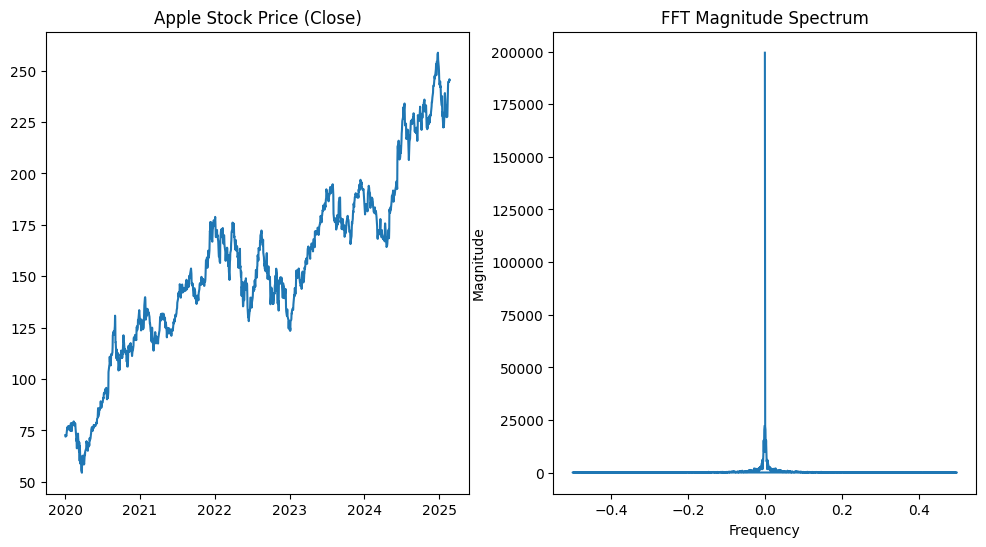

Top 5 dominant frequencies: [-0.00154799  0.00154799 -0.00077399  0.00077399  0.        ]
Epoch 1/20


/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.0717
Epoch 2/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0027
Epoch 3/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 9.4835e-04
Epoch 4/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 6.5639e-04
Epoch 5/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 7.0607e-04
Epoch 6/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 6.7149e-04
Epoch 7/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 6.0526e-04
Epoch 8/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 6.4682e-04
Epoch 9/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 6.3802e-04
Epoch 10/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 6.4640e-04
Epoch 11/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 6.3856e-04
Epoch 12/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 6.8165e-04
Epoch 13/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 6.0901e-04
Epoch 14/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 6.1971e-04
Epoch 15/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/st

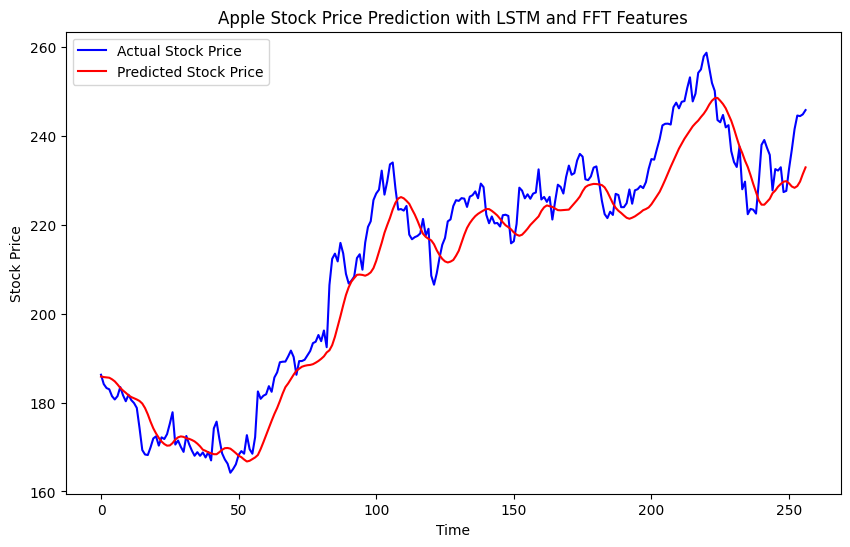

Mean Squared Error: 51.13508504017428


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.fft import fft
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense
from sklearn.model_selection import train_test_split
import yfinance as yf


# Use the 'Close' column for stock price prediction
stock_prices = data2['Close'].values

# Step 2: Apply Fast Fourier Transform (FFT)
stock_prices_fft = fft(stock_prices)

# Step 3: Identify the dominant frequency components
frequencies = np.fft.fftfreq(len(stock_prices))
magnitude = np.abs(stock_prices_fft)  # Magnitude of frequency components

# Visualize the stock price and FFT
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.plot(apple_stock.index, stock_prices)
plt.title('Apple Stock Price (Close)')

plt.subplot(1, 2, 2)
plt.plot(frequencies, magnitude)
plt.title('FFT Magnitude Spectrum')
plt.xlabel('Frequency')
plt.ylabel('Magnitude')
plt.show()

# Step 4: Extract dominant frequency components
# Choose the top N frequencies with the highest magnitude
N = 5  # Number of dominant frequencies to use
dominant_frequencies = np.argsort(magnitude)[-N:]  # Indices of the top N dominant frequencies
print(f"Top {N} dominant frequencies: {frequencies[dominant_frequencies]}")

# Extract the corresponding frequency components to use as features
extracted_features = stock_prices_fft[dominant_frequencies]

# Step 5: Prepare the data for LSTM
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(stock_prices.reshape(-1, 1))

# Define function to create data for LSTM
def create_dataset(data, time_step=1):
    X, y = [], []
    for i in range(len(data) - time_step - 1):
        X.append(data[i:(i + time_step), 0])
        y.append(data[i + time_step, 0])
    return np.array(X), np.array(y)

# Use last N time steps to predict the next value (you can adjust N)
time_step = 10
X, y = create_dataset(scaled_data, time_step)

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)

# Reshape the data for LSTM [samples, time steps, features]
X_train = X_train.reshape(X_train.shape[0], X_train.shape[1], 1)
X_test = X_test.reshape(X_test.shape[0], X_test.shape[1], 1)

# Step 6: Build the LSTM model
model = Sequential()
model.add(LSTM(units=50, return_sequences=True, input_shape=(X_train.shape[1], 1)))
model.add(LSTM(units=50))
model.add(Dense(units=1))  # Output layer

# Compile the model
model.compile(optimizer='adam', loss='mean_squared_error')

# Step 7: Train the model
model.fit(X_train, y_train, epochs=20, batch_size=32)

# Step 8: Predict and visualize the results
predicted_stock_prices = model.predict(X_test)

# Inverse transform the predicted and actual prices to get the original scale
predicted_stock_prices = scaler.inverse_transform(predicted_stock_prices)
y_test_actual = scaler.inverse_transform(y_test.reshape(-1, 1))

# Plot the results
plt.figure(figsize=(10, 6))
plt.plot(y_test_actual, color='blue', label='Actual Stock Price')
plt.plot(predicted_stock_prices, color='red', label='Predicted Stock Price')
plt.title('Apple Stock Price Prediction with LSTM and FFT Features')
plt.xlabel('Time')
plt.ylabel('Stock Price')
plt.legend()
plt.show()

# Step 9: Evaluate model performance
mse = np.mean((predicted_stock_prices - y_test_actual) ** 2)
print(f"Mean Squared Error: {mse}")


In [ ]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.fft import fft
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense
from sklearn.model_selection import train_test_split
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout, Bidirectional, Attention, Concatenate, Flatten
from tensorflow.keras.models import Model

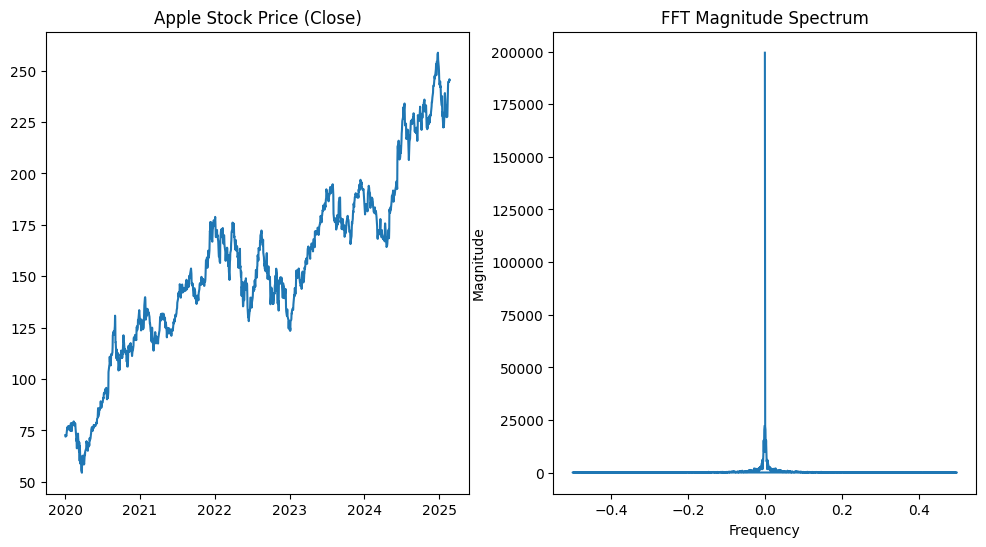

Top 5 dominant frequencies: [-0.00154799  0.00154799 -0.00077399  0.00077399  0.        ]
Epoch 1/100


/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.1961
Epoch 2/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.1050
Epoch 3/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0346
Epoch 4/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0045
Epoch 5/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0041
Epoch 6/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0032
Epoch 7/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0032
Epoch 8/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0027
Epoch 9/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0027
Epoch 10/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0027
Epoch 11/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0026
Epoch 12/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0025
Epoch 13/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0021
Epoch 14/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0023
Epoch 15/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0022
Epoch 16/100
16/

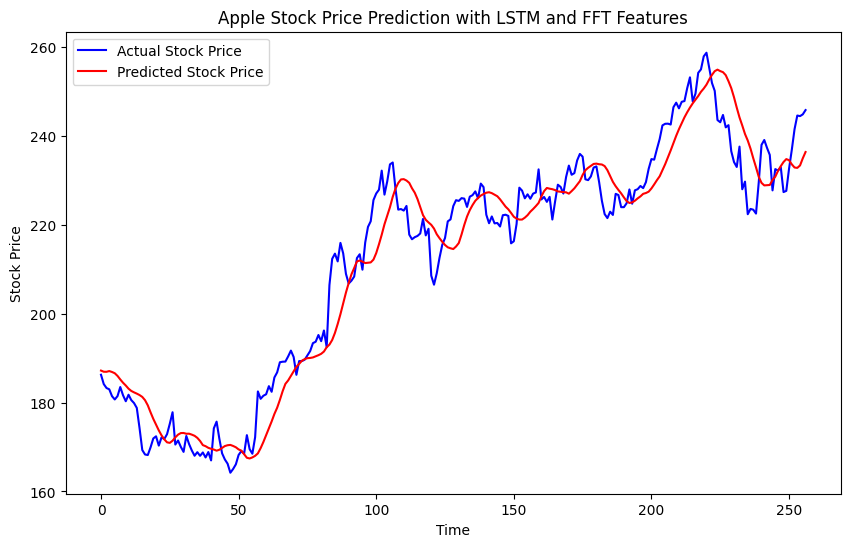

Mean Squared Error: 45.68128229705219


In [ ]:
# Use the 'Close' column for stock price prediction
stock_prices = data2['Close'].values

# Step 2: Apply Fast Fourier Transform (FFT)
stock_prices_fft = fft(stock_prices)

# Step 3: Identify the dominant frequency components
frequencies = np.fft.fftfreq(len(stock_prices))
magnitude = np.abs(stock_prices_fft)  # Magnitude of frequency components

# Visualize the stock price and FFT
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.plot(apple_stock.index, stock_prices)
plt.title('Apple Stock Price (Close)')

plt.subplot(1, 2, 2)
plt.plot(frequencies, magnitude)
plt.title('FFT Magnitude Spectrum')
plt.xlabel('Frequency')
plt.ylabel('Magnitude')
plt.show()

# Step 4: Extract dominant frequency components
# Choose the top N frequencies with the highest magnitude
N = 5  # Number of dominant frequencies to use
dominant_frequencies = np.argsort(magnitude)[-N:]  # Indices of the top N dominant frequencies
print(f"Top {N} dominant frequencies: {frequencies[dominant_frequencies]}")

# Extract the corresponding frequency components to use as features
extracted_features = stock_prices_fft[dominant_frequencies]

# Step 5: Prepare the data for LSTM
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(stock_prices.reshape(-1, 1))

# Define function to create data for LSTM
def create_dataset(data, time_step=1):
    X, y = [], []
    for i in range(len(data) - time_step - 1):
        X.append(data[i:(i + time_step), 0])
        y.append(data[i + time_step, 0])
    return np.array(X), np.array(y)

# Use last N time steps to predict the next value (you can adjust N)
time_step = 10
X, y = create_dataset(scaled_data, time_step)

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)

# Reshape the data for LSTM [samples, time steps, features]
X_train = X_train.reshape(X_train.shape[0], X_train.shape[1], 1)
X_test = X_test.reshape(X_test.shape[0], X_test.shape[1], 1)

# Step 6: Build the LSTM model
model = Sequential()
model.add(LSTM(units=100, return_sequences=True, input_shape=(X_train.shape[1], 1)))
model.add(LSTM(units=100))
model.add(Dropout(0.2))
model.add(Dense(units=1))  # Output layer


# Compile the model
optimizer = tf.keras.optimizers.Adam(learning_rate=0.0001)
model.compile(optimizer=optimizer, loss='mean_squared_error')

# Step 7: Train the model
model.fit(X_train, y_train, epochs=100, batch_size=64)

# Step 8: Predict and visualize the results
predicted_stock_prices = model.predict(X_test)

# Inverse transform the predicted and actual prices to get the original scale
predicted_stock_prices = scaler.inverse_transform(predicted_stock_prices)
y_test_actual = scaler.inverse_transform(y_test.reshape(-1, 1))

# Plot the results
plt.figure(figsize=(10, 6))
plt.plot(y_test_actual, color='blue', label='Actual Stock Price')
plt.plot(predicted_stock_prices, color='red', label='Predicted Stock Price')
plt.title('Apple Stock Price Prediction with LSTM and FFT Features')
plt.xlabel('Time')
plt.ylabel('Stock Price')
plt.legend()
plt.show()

# Step 9: Evaluate model performance
mse = np.mean((predicted_stock_prices - y_test_actual) ** 2)
print(f"Mean Squared Error: {mse}")


##Model 3

[*********************100%***********************]  1 of 1 completed

Epoch 1/100



/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:837: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/deterministic.py:308: UserWarning: Only PeriodIndexes, DatetimeIndexes with a frequency set, RangesIndexes, and Index with a unit increment support extending. The index is set will contain the p

4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 0.4244
Epoch 2/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.3893
Epoch 3/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.3308
Epoch 4/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.2952
Epoch 5/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.2498
Epoch 6/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.2136
Epoch 7/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.1781
Epoch 8/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.1408
Epoch 9/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.1079
Epoch 10/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0778
Epoch 11/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0529
Epoch 12/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0319
Epoch 13/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0167
Epoch 14/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0091
Epoch 15/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0053
Epoch 16/100
4/4 ━━━━━━━━━━━━━━

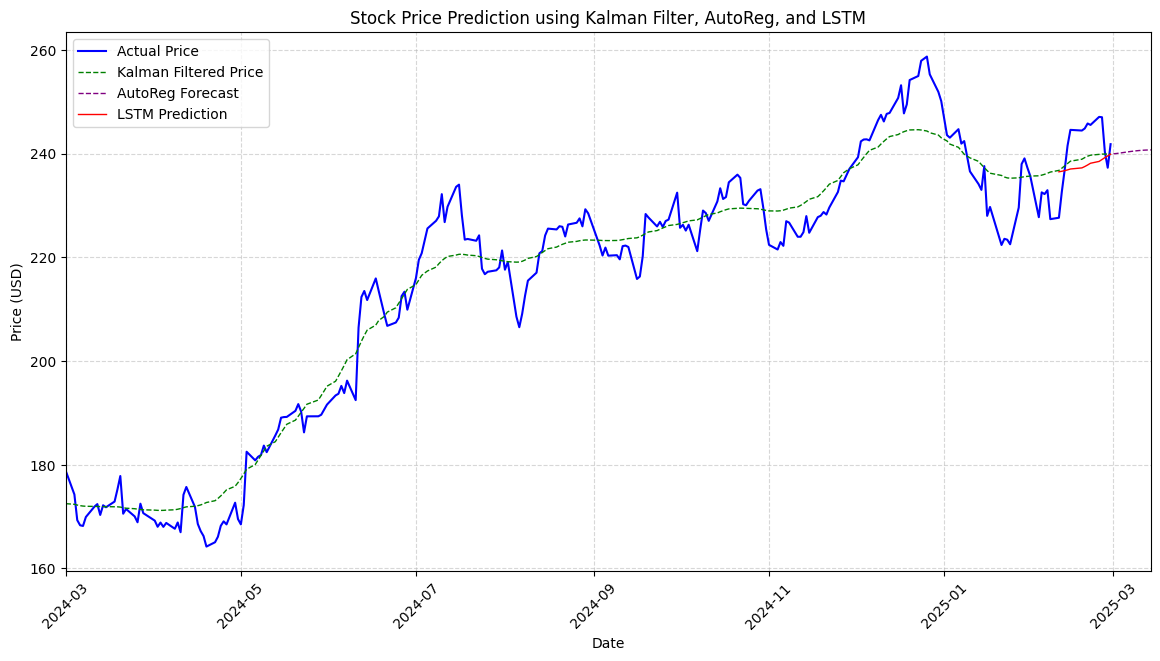

In [ ]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.ar_model import AutoReg
from pykalman import KalmanFilter
from scipy.fftpack import fft
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
import tensorflow as tf

# ดึงข้อมูลราคาหุ้น AAPL
ticker = "AAPL"
df = yf.download(ticker, period="1y", interval="1d")[['Close']]
df.dropna(inplace=True)

# ======= ใช้ Kalman Filter =======
kf = KalmanFilter(
    transition_matrices=[1],
    observation_matrices=[1],
    initial_state_mean=df['Close'].iloc[0],
    initial_state_covariance=1,
    observation_covariance=1,
    transition_covariance=0.01
)
state_means, _ = kf.smooth(df['Close'].values)
df['Kalman_Filtered'] = state_means.flatten()

# ======= ใช้ FFT เพื่อดึงคุณสมบัติ =======
stock_prices = df['Kalman_Filtered'].values
stock_prices_fft = fft(stock_prices)
frequencies = np.fft.fftfreq(len(stock_prices))
magnitude = np.abs(stock_prices_fft)
N = 5  # เลือก 5 ความถี่สำคัญที่สุด
dominant_frequencies = np.argsort(magnitude)[-N:]
fft_features = stock_prices_fft[dominant_frequencies].real  # ใช้เฉพาะส่วนจริง

# ======= ใช้ AutoReg =======
LOOKBACK_LENGTH = 150
FORECAST_DAYS = 14
train_data = df['Kalman_Filtered'][-LOOKBACK_LENGTH:]
model_ar = AutoReg(train_data, lags=5).fit()
forecast_values = model_ar.predict(start=len(train_data), end=len(train_data) + FORECAST_DAYS - 1)
forecast_dates = pd.date_range(df.index[-1], periods=FORECAST_DAYS+1, freq='D')[1:]
forecast_df = pd.DataFrame({'Date': forecast_dates, 'Forecast': forecast_values}).set_index('Date')

# ======= เตรียมข้อมูลสำหรับ LSTM =======
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(stock_prices.reshape(-1, 1))

def create_dataset(data, time_step=10):
    X, y = [], []
    for i in range(len(data) - time_step - 1):
        X.append(data[i:(i + time_step), 0])
        y.append(data[i + time_step, 0])
    return np.array(X), np.array(y)

time_step = 10
X, y = create_dataset(scaled_data, time_step)
X_train, X_test, y_train, y_test = X[:-FORECAST_DAYS], X[-FORECAST_DAYS:], y[:-FORECAST_DAYS], y[-FORECAST_DAYS:]
X_train = X_train.reshape(X_train.shape[0], X_train.shape[1], 1)
X_test = X_test.reshape(X_test.shape[0], X_test.shape[1], 1)

# ======= สร้างโมเดล LSTM =======
model_lstm = Sequential([
    LSTM(100, return_sequences=True, input_shape=(X_train.shape[1], 1)),
    LSTM(100),
    Dropout(0.2),
    Dense(1)
])
model_lstm.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001), loss='mean_squared_error')

# ======= Train โมเดล =======
model_lstm.fit(X_train, y_train, epochs=100, batch_size=64)

# ======= Predict =======
predicted_stock_prices = model_lstm.predict(X_test)
predicted_stock_prices = scaler.inverse_transform(predicted_stock_prices)
y_test_actual = scaler.inverse_transform(y_test.reshape(-1, 1))



# สร้าง DataFrame สำหรับเก็บค่าพยากรณ์ของ LSTM
lstm_predictions = pd.DataFrame({
    'Date': df.index[-len(predicted_stock_prices):],
    'LSTM_Predicted': predicted_stock_prices.flatten()
}).set_index('Date')

# ======= Plot ผลลัพธ์ =======
plt.figure(figsize=(14, 7))

# ราคาจริง
plt.plot(df.index, df['Close'], label='Actual Price', color='blue')

# Kalman Filter (เส้นบาง + เส้นประ)
plt.plot(df.index, df['Kalman_Filtered'], label='Kalman Filtered Price',
         color='green', linestyle='--', linewidth=1)

# AutoReg Forecast (เส้นบาง + เส้นประ)
plt.plot(forecast_df.index, forecast_df['Forecast'], label='AutoReg Forecast',
         color='purple', linestyle='--', linewidth=1)

# LSTM Prediction (เส้นแดง บาง)
plt.plot(lstm_predictions.index, lstm_predictions['LSTM_Predicted'],
         label='LSTM Prediction', color='red', linestyle='-', linewidth=1)

# ปรับแต่งกราฟ
plt.xlabel("Date")
plt.ylabel("Price (USD)")
plt.title("Stock Price Prediction using Kalman Filter, AutoReg, and LSTM")
plt.legend(loc="upper left")
plt.xticks(rotation=45)
plt.grid(True, linestyle="--", alpha=0.5)
plt.xlim(df.index.min(), forecast_df.index.max())  # กำหนดช่วงเวลาให้พอดี

plt.show()




[*********************100%***********************]  1 of 1 completed

Epoch 1/100



/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:837: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/deterministic.py:308: UserWarning: Only PeriodIndexes, DatetimeIndexes with a frequency set, RangesIndexes, and Index with a unit increment support extending. The index is set will contain the p

4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - loss: 0.4310
Epoch 2/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.3758
Epoch 3/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.3391
Epoch 4/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.2849
Epoch 5/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.2444
Epoch 6/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.2111
Epoch 7/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.1752
Epoch 8/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.1415
Epoch 9/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.1016
Epoch 10/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0705
Epoch 11/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0417
Epoch 12/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0261
Epoch 13/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0120
Epoch 14/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0062
Epoch 15/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0055
Epoch 16/100
4/4 ━━━━━━━━━━━━━━

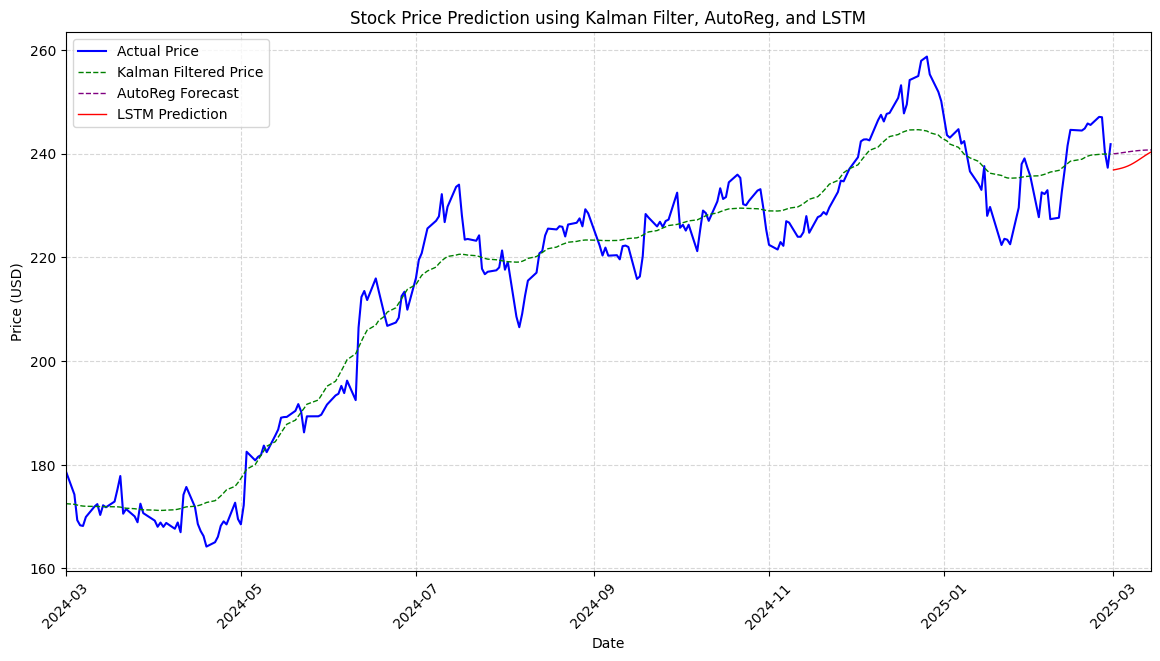

In [ ]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.ar_model import AutoReg
from pykalman import KalmanFilter
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
import tensorflow as tf

# ======= ดึงข้อมูลราคาหุ้น AAPL =======
ticker = "AAPL"
df = yf.download(ticker, period="1y", interval="1d")[['Close']]
df.dropna(inplace=True)

# ======= ใช้ Kalman Filter =======
kf = KalmanFilter(
    transition_matrices=[1],
    observation_matrices=[1],
    initial_state_mean=df['Close'].iloc[0],
    initial_state_covariance=1,
    observation_covariance=1,
    transition_covariance=0.01
)
state_means, _ = kf.smooth(df['Close'].values)
df['Kalman_Filtered'] = state_means.flatten()

# ======= ตั้งค่าพยากรณ์ =======
LOOKBACK_LENGTH = 150
FORECAST_DAYS = 14

# ======= ใช้ AutoReg =======
train_data = df['Kalman_Filtered'][-LOOKBACK_LENGTH:]
model_ar = AutoReg(train_data, lags=5).fit()
forecast_values = model_ar.predict(start=len(train_data), end=len(train_data) + FORECAST_DAYS - 1)
forecast_dates = pd.date_range(df.index[-1], periods=FORECAST_DAYS+1, freq='D')[1:]
forecast_df = pd.DataFrame({'Date': forecast_dates, 'AutoReg_Forecast': forecast_values}).set_index('Date')

# ======= เตรียมข้อมูลสำหรับ LSTM =======
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(df['Kalman_Filtered'].values.reshape(-1, 1))

def create_dataset(data, time_step=10):
    X, y = [], []
    for i in range(len(data) - time_step - 1):
        X.append(data[i:(i + time_step), 0])
        y.append(data[i + time_step, 0])
    return np.array(X), np.array(y)

time_step = 10
X, y = create_dataset(scaled_data, time_step)
X_train, X_test, y_train, y_test = X[:-FORECAST_DAYS], X[-FORECAST_DAYS:], y[:-FORECAST_DAYS], y[-FORECAST_DAYS:]
X_train = X_train.reshape(X_train.shape[0], X_train.shape[1], 1)
X_test = X_test.reshape(X_test.shape[0], X_test.shape[1], 1)

# ======= สร้างโมเดล LSTM =======
model_lstm = Sequential([
    LSTM(100, return_sequences=True, input_shape=(X_train.shape[1], 1)),
    LSTM(100),
    Dropout(0.2),
    Dense(1)
])
model_lstm.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001), loss='mean_squared_error')

# ======= Train โมเดล =======
model_lstm.fit(X_train, y_train, epochs=100, batch_size=64)

# ======= Predict =======
predicted_stock_prices = model_lstm.predict(X_test)
predicted_stock_prices = scaler.inverse_transform(predicted_stock_prices)

# ======= จัดการช่วงเวลาของ LSTM =======
lstm_predictions = pd.DataFrame({
    'Date': forecast_dates,
    'LSTM_Predicted': predicted_stock_prices.flatten()
}).set_index('Date')

# ======= คำนวณ RMSE เพื่อเปรียบเทียบโมเดล =======
from sklearn.metrics import mean_squared_error

rmse_autoreg = np.sqrt(mean_squared_error(df['Close'].iloc[-FORECAST_DAYS:], forecast_df['AutoReg_Forecast']))
rmse_lstm = np.sqrt(mean_squared_error(df['Close'].iloc[-FORECAST_DAYS:], lstm_predictions['LSTM_Predicted']))

print(f"RMSE AutoReg: {rmse_autoreg:.4f}")
print(f"RMSE LSTM: {rmse_lstm:.4f}")

# ======= Plot ผลลัพธ์ =======
plt.figure(figsize=(14, 7))

# ราคาจริง
plt.plot(df.index, df['Close'], label='Actual Price', color='blue')

# Kalman Filter (เส้นบาง + เส้นประ)
plt.plot(df.index, df['Kalman_Filtered'], label='Kalman Filtered Price',
         color='green', linestyle='--', linewidth=1)

# AutoReg Forecast (เส้นบาง + เส้นประ)
plt.plot(forecast_df.index, forecast_df['AutoReg_Forecast'], label='AutoReg Forecast',
         color='purple', linestyle='--', linewidth=1)

# LSTM Prediction (เส้นแดง บาง)
plt.plot(lstm_predictions.index, lstm_predictions['LSTM_Predicted'],
         label='LSTM Prediction', color='red', linestyle='-', linewidth=1)

# ปรับแต่งกราฟ
plt.xlabel("Date")
plt.ylabel("Price (USD)")
plt.title("Stock Price Prediction using Kalman Filter, AutoReg, and LSTM")
plt.legend(loc="upper left")
plt.xticks(rotation=45)
plt.grid(True, linestyle="--", alpha=0.5)
plt.xlim(df.index.min(), forecast_df.index.max())  # กำหนดช่วงเวลาให้พอดี

plt.show()


/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:837: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/deterministic.py:308: UserWarning: Only PeriodIndexes, DatetimeIndexes with a frequency set, RangesIndexes, and Index with a unit increment support extending. The index is set will contain the po

Epoch 1/150
8/8 ━━━━━━━━━━━━━━━━━━━━ 5s 124ms/step - loss: 0.4667 - val_loss: 0.7812
Epoch 2/150
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.3943 - val_loss: 0.6384
Epoch 3/150
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.3085 - val_loss: 0.4932
Epoch 4/150
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.2359 - val_loss: 0.3399
Epoch 5/150
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.1554 - val_loss: 0.1881
Epoch 6/150
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0797 - val_loss: 0.0531
Epoch 7/150
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.0227 - val_loss: 2.2874e-04
Epoch 8/150
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.0125 - val_loss: 0.0021
Epoch 9/150
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0133 - val_loss: 7.9490e-04
Epoch 10/150
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0127 - val_loss: 0.0041
Epoch 11/150
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0082 - val_loss: 0.0016
Epoch 12/150
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0100

/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128200 (\N{CHART WITH UPWARDS TREND}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


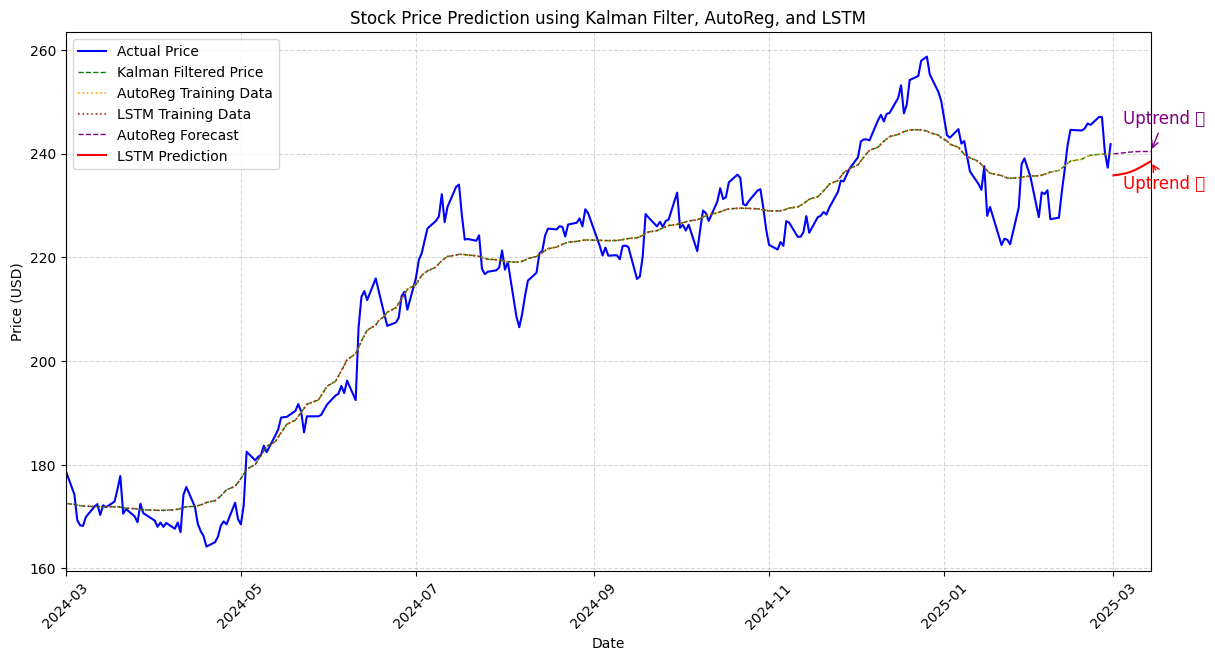

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.ar_model import AutoReg
from pykalman import KalmanFilter
from scipy.fftpack import fft
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
import tensorflow as tf
from sklearn.metrics import mean_squared_error


# ========== ✅ ใช้ Kalman Filter ==========
kf = KalmanFilter(
    transition_matrices=[1],
    observation_matrices=[1],
    initial_state_mean=df['Close'].iloc[0],
    initial_state_covariance=1,
    observation_covariance=1,
    transition_covariance=0.01
)
state_means, _ = kf.smooth(df['Close'].values)
df['Kalman_Filtered'] = state_means.flatten()

# ========== ✅ ใช้ FFT ==========
# ✅ คำนวณ FFT
stock_prices = df['Kalman_Filtered'].values
stock_prices_fft = fft(stock_prices)
frequencies = np.fft.fftfreq(len(stock_prices))
magnitude = np.abs(stock_prices_fft)

# ✅ เลือก 5 ความถี่สำคัญที่สุด (เรียงจากมากไปน้อย)
N = 5
dominant_indices = np.argpartition(magnitude, -N)[-N:]
dominant_indices = dominant_indices[np.argsort(magnitude[dominant_indices])[::-1]]  # เรียงจากมากไปน้อย

# ✅ ดึงค่าความถี่ที่สำคัญที่สุด (ไม่รวม DC ถ้าจำเป็น)
dominant_frequencies = frequencies[dominant_indices]
fft_features = stock_prices_fft[dominant_indices].real  # ใช้เฉพาะส่วนจริง



# ========== ✅ ใช้ AutoReg ==========
LOOKBACK_LENGTH = 200
FORECAST_DAYS = 14
train_data = df['Kalman_Filtered'][-LOOKBACK_LENGTH:]

model_ar = AutoReg(train_data, lags=5).fit()
forecast_values = model_ar.predict(start=len(train_data), end=len(train_data) + FORECAST_DAYS - 1)
forecast_dates = pd.date_range(df.index[-1], periods=FORECAST_DAYS+1, freq='D')[1:]
df_forecast = pd.DataFrame({'Date': forecast_dates, 'AutoReg_Forecast': forecast_values}).set_index('Date')

# ========== ✅ เตรียมข้อมูลสำหรับ LSTM ==========
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(df['Kalman_Filtered'].values.reshape(-1, 1))

def create_dataset(data, time_step=10):
    X, y = [], []
    for i in range(len(data) - time_step - 1):
        X.append(data[i:(i + time_step), 0])
        y.append(data[i + time_step, 0])
    return np.array(X), np.array(y)

time_step = 10
X, y = create_dataset(scaled_data, time_step)
X_train, X_test, y_train, y_test = X[:-FORECAST_DAYS], X[-FORECAST_DAYS:], y[:-FORECAST_DAYS], y[-FORECAST_DAYS:]

X_train = X_train.reshape(X_train.shape[0], X_train.shape[1], 1)
X_test = X_test.reshape(X_test.shape[0], X_test.shape[1], 1)

# ========== ✅ ปรับโมเดล LSTM ==========

model_lstm = Sequential([
    LSTM(100, return_sequences=True, input_shape=(X_train.shape[1], 1)),
    Dropout(0.3),  # เพิ่ม Dropout 30% หลัง LSTM Layer แรก
    LSTM(100, return_sequences=True),
    Dropout(0.3),  # เพิ่ม Dropout อีกครั้ง
    LSTM(100),
    Dropout(0.3),  # เพิ่ม Dropout ก่อน Fully Connected Layer
    Dense(1)
])

# คอมไพล์โมเดล
model_lstm.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001), loss='mean_squared_error')

# Train โมเดล
model_lstm.fit(X_train, y_train, epochs=150, batch_size=32, verbose=1, validation_data=(X_test, y_test))

# ========== ✅ Predict ==========
predicted_stock_prices = model_lstm.predict(X_test)
predicted_stock_prices = scaler.inverse_transform(predicted_stock_prices)

df_forecast['LSTM_Predicted'] = predicted_stock_prices.flatten()

# ========== ✅ คำนวณ RMSE ==========
valid_autoreg = df_forecast[['AutoReg_Forecast']].dropna()
valid_lstm = df_forecast[['LSTM_Predicted']].dropna()

if not valid_autoreg.empty:
    rmse_autoreg = np.sqrt(mean_squared_error(df['Close'].iloc[-FORECAST_DAYS:], valid_autoreg['AutoReg_Forecast']))
    print(f"RMSE AutoReg: {rmse_autoreg:.4f}")
else:
    print("AutoReg ไม่สามารถพยากรณ์ข้อมูลได้ (ค่า NaN ทั้งหมด)")

if not valid_lstm.empty:
    rmse_lstm = np.sqrt(mean_squared_error(df['Close'].iloc[-FORECAST_DAYS:], valid_lstm['LSTM_Predicted']))
    print(f"RMSE LSTM: {rmse_lstm:.4f}")
else:
    print("LSTM ไม่สามารถพยากรณ์ข้อมูลได้ (ค่า NaN ทั้งหมด)")


# ปรับให้ขนาดตรงกัน
close_prices = df['Close'].iloc[-FORECAST_DAYS:].values.flatten()
autoreg_forecast = valid_autoreg['AutoReg_Forecast'].values.flatten()
lstm_forecast = valid_lstm['LSTM_Predicted'].values.flatten()

# คำนวณ Correlation
correlation_autoreg = np.corrcoef(close_prices, autoreg_forecast)[0, 1]
correlation_lstm = np.corrcoef(close_prices, lstm_forecast)[0, 1]

# ตรวจสอบแนวโน้ม
autoreg_trend = np.diff(autoreg_forecast)
lstm_trend = np.diff(lstm_forecast)

autoreg_trend_label = "Uptrend \U0001F4C8" if np.mean(autoreg_trend) > 0 else "Downtrend \U0001F4C9" if np.mean(autoreg_trend) < 0 else "Sideways \u27A1"
lstm_trend_label = "Uptrend \U0001F4C8" if np.mean(lstm_trend) > 0 else "Downtrend \U0001F4C9" if np.mean(lstm_trend) < 0 else "Sideways \u27A1"

# ✅ Plot ผลลัพธ์
plt.figure(figsize=(14, 7))

# ✅ ราคาจริง
plt.plot(df.index, df['Close'], label='Actual Price', color='blue')

# ✅ Kalman Filter
plt.plot(df.index, df['Kalman_Filtered'], label='Kalman Filtered Price', linestyle='--', color='green', linewidth=1)

# ✅ ข้อมูลที่ใช้ Train AutoReg
plt.plot(df.index[-LOOKBACK_LENGTH:], df['Kalman_Filtered'][-LOOKBACK_LENGTH:], label='AutoReg Training Data', linestyle=':', color='orange', linewidth=1.2)

# ✅ ข้อมูลที่ใช้ Train LSTM
plt.plot(df.index[:-FORECAST_DAYS], df['Kalman_Filtered'][:-FORECAST_DAYS], label='LSTM Training Data', linestyle=':', color='brown', linewidth=1.2)

# ✅ AutoReg Forecast
plt.plot(df_forecast.index, df_forecast['AutoReg_Forecast'], label='AutoReg Forecast', linestyle='--', color='purple', linewidth=1)

# ✅ LSTM Prediction
plt.plot(df_forecast.index, df_forecast['LSTM_Predicted'], label='LSTM Prediction', linestyle='-', color='red', linewidth=1.5)

# ✅ เพิ่มลูกศรแสดงแนวโน้ม
plt.annotate(autoreg_trend_label, xy=(df_forecast.index[-1], df_forecast['AutoReg_Forecast'].iloc[-1]),
             xytext=(-20, 20), textcoords='offset points', fontsize=12, color='purple', arrowprops=dict(arrowstyle='->', color='purple'))
plt.annotate(lstm_trend_label, xy=(df_forecast.index[-1], df_forecast['LSTM_Predicted'].iloc[-1]),
             xytext=(-20, -20), textcoords='offset points', fontsize=12, color='red', arrowprops=dict(arrowstyle='->', color='red'))

# ✅ ปรับแต่งกราฟ
plt.xlabel("Date")
plt.ylabel("Price (USD)")
plt.title("Stock Price Prediction using Kalman Filter, AutoReg, and LSTM")
plt.legend(loc="upper left")
plt.xticks(rotation=45)
plt.grid(True, linestyle="--", alpha=0.5)
plt.xlim(df.index.min(), df_forecast.index.max())

plt.show()




##Model 4

In [ ]:
import yfinance as yf

# Download data
gs = yf.download("GS", start="2011-01-01", end="2021-01-01")

[*********************100%***********************]  1 of 1 completed


In [ ]:
!pip install pmdarima

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 20.1 MB/s eta 0:00:00


In [ ]:
import pandas as pd
# Preprocess data
dataset_ex_df = gs.copy()
dataset_ex_df = dataset_ex_df.reset_index()
dataset_ex_df['Date'] = pd.to_datetime(dataset_ex_df['Date'])
dataset_ex_df.set_index('Date', inplace=True)

In [ ]:
type(dataset_ex_df['Close'])

pandas.core.frame.DataFrame

In [ ]:
from pmdarima.arima import auto_arima


In [ ]:
from pmdarima.arima import auto_arima

# Auto ARIMA to select optimal ARIMA parameters
model = auto_arima(dataset_ex_df['Close'], seasonal=False, trace=True)
print(model.summary())

/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/usr/local/lib/python3.11

Performing stepwise search to minimize aic
 ARIMA(2,1,2)(0,0,0)[0] intercept   : AIC=12131.225, Time=0.79 sec
 ARIMA(0,1,0)(0,0,0)[0] intercept   : AIC=12156.963, Time=0.05 sec
 ARIMA(1,1,0)(0,0,0)[0] intercept   : AIC=12139.064, Time=0.15 sec


/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


 ARIMA(0,1,1)(0,0,0)[0] intercept   : AIC=12141.649, Time=0.20 sec
 ARIMA(0,1,0)(0,0,0)[0]             : AIC=12155.548, Time=0.04 sec


/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


...

 ARIMA(1,1,2)(0,0,0)[0]             : AIC=12127.939, Time=0.49 sec


/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


 ARIMA(0,1,3)(0,0,0)[0]             : AIC=12127.633, Time=0.25 sec
 ARIMA(1,1,1)(0,0,0)[0]             : AIC=12130.303, Time=0.13 sec


/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


 ARIMA(1,1,3)(0,0,0)[0]             : AIC=12128.972, Time=0.52 sec

Best model:  ARIMA(0,1,2)(0,0,0)[0]          
Total fit time: 6.675 seconds
                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                 2517
Model:               SARIMAX(0, 1, 2)   Log Likelihood               -6060.438
Date:                Mon, 03 Mar 2025   AIC                          12126.876
Time:                        13:18:07   BIC                          12144.367
Sample:                             0   HQIC                         12133.224
                               - 2517                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.0795      0.009     -9.000      0.000      -0.097

In [ ]:
import numpy as np
from statsmodels.tsa.arima.model import ARIMA

# Define the ARIMA model
def arima_forecast(history):
    model = ARIMA(history, order=(0, 1, 2))  # Use best order from auto_arima
    model_fit = model.fit()

    # Make the prediction
    yhat = model_fit.forecast()[0]
    return yhat

# Ensure only the 'Close' column is used
X = dataset_ex_df['Close'].values  # Extract 'Close' column only
size = int(len(X) * 0.8)
train, test = X[:size], X[size:]

# Walk-forward validation
history = list(train)  # Convert to list for appending
predictions = []

for t in range(len(test)):
    yhat = arima_forecast(history)  # Predict next value
    predictions.append(yhat)
    history.append(test[t])  # Add actual value to history


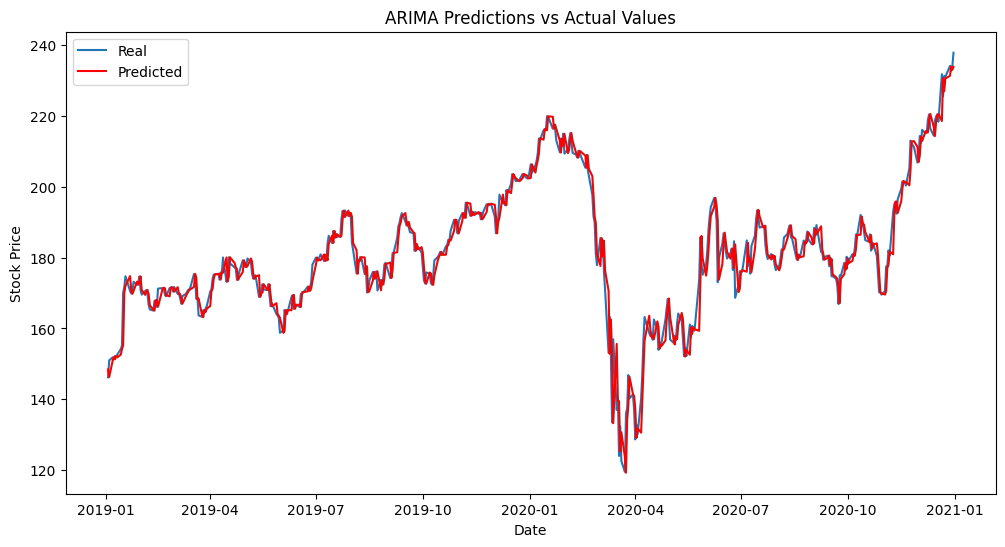

In [ ]:
plt.figure(figsize=(12, 6), dpi=100)
plt.plot(dataset_ex_df.iloc[size:,:].index, test, label='Real')
plt.plot(dataset_ex_df.iloc[size:,:].index, predictions, color='red', label='Predicted')
plt.title('ARIMA Predictions vs Actual Values')
plt.xlabel('Date')
plt.ylabel('Stock Price')
plt.legend()
plt.show()

/usr/local/lib/python3.11/dist-packages/matplotlib/cbook.py:1709: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/usr/local/lib/python3.11/dist-packages/matplotlib/cbook.py:1345: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


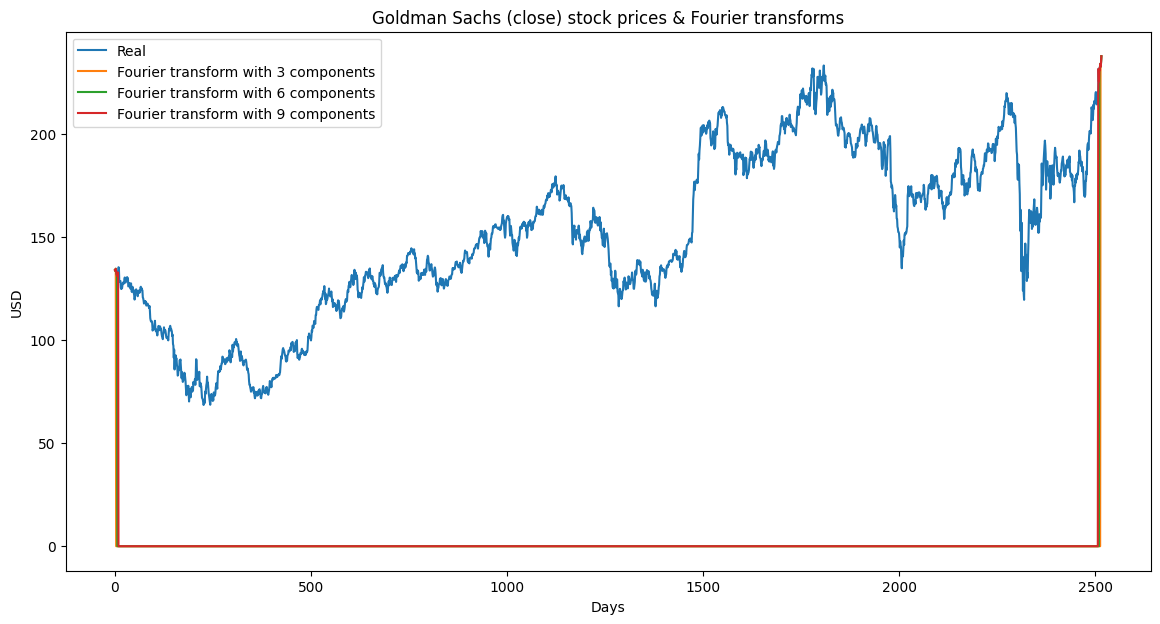

In [ ]:
# Calculate the Fourier Transform
data_FT = dataset_ex_df[['Close']]
close_fft = np.fft.fft(np.asarray(data_FT['Close'].values.tolist()))
fft_df = pd.DataFrame({'fft': close_fft.flatten()})
fft_df['absolute'] = fft_df['fft'].apply(lambda x: np.abs(x))
fft_df['angle'] = fft_df['fft'].apply(lambda x: np.angle(x))

# Plot the Fourier Transforms
plt.figure(figsize=(14, 7), dpi=100)
plt.plot(np.asarray(data_FT['Close'].values.tolist()),  label='Real')
for num_ in [3, 6, 9]:
    fft_list_m10= np.copy(close_fft); fft_list_m10[num_:-num_]=0
    plt.plot(np.fft.ifft(fft_list_m10), label='Fourier transform with {} components'.format(num_))
plt.xlabel('Days')
plt.ylabel('USD')
plt.title('Goldman Sachs (close) stock prices & Fourier transforms')
plt.legend()
plt.show()

In [ ]:
# Calculate EMA
def ema(close, period=20):
    return close.ewm(span=period, adjust=False).mean()

# Calculate RSI
def rsi(close, period=14):
    delta = close.diff()
    gain, loss = delta.copy(), delta.copy()
    gain[gain < 0] = 0
    loss[loss > 0] = 0
    avg_gain = gain.rolling(period).mean()
    avg_loss = abs(loss.rolling(period).mean())
    rs = avg_gain / avg_loss
    rsi = 100.0 - (100.0 / (1.0 + rs))
    return rsi

# Calculate MACD
def macd(close, fast_period=12, slow_period=26, signal_period=9):
    fast_ema = close.ewm(span=fast_period, adjust=False).mean()
    slow_ema = close.ewm(span=slow_period, adjust=False).mean()
    macd_line = fast_ema - slow_ema
    signal_line = macd_line.ewm(span=signal_period, adjust=False).mean()
    histogram = macd_line - signal_line
    return macd_line

# Calculate OBV
def obv(close, volume):
    obv = np.where(close > close.shift(), volume, np.where(close < close.shift(), -volume, 0)).cumsum()
    return obv

In [ ]:
# Add technical indicators to dataset DF
dataset_ex_df['ema_20'] = ema(df["Close"], 20)
dataset_ex_df['ema_50'] = ema(df["Close"], 50)
dataset_ex_df['ema_100'] = ema(df["Close"], 100)

dataset_ex_df['rsi'] = rsi(df["Close"])
dataset_ex_df['macd'] = macd(df["Close"])
dataset_ex_df['obv'] = obv(df["Close"], df["Volume"])

# Create arima DF using predictions
arima_df = pd.DataFrame(history, index=dataset_ex_df.index, columns=['ARIMA'])

# Set Fourier Transforms DF
fft_df.reset_index(inplace=True)
fft_df['index'] = pd.to_datetime(dataset_ex_df.index)
fft_df.set_index('index', inplace=True)
fft_df_real = pd.DataFrame(np.real(fft_df['fft']), index=fft_df.index, columns=['Fourier_real'])
fft_df_imag = pd.DataFrame(np.imag(fft_df['fft']), index=fft_df.index, columns=['Fourier_imag'])

# Technical Indicators DF
technical_indicators_df = dataset_ex_df[['ema_20', 'ema_50', 'ema_100', 'rsi', 'macd', 'obv', 'Close']]

# Merge DF
merged_df = pd.concat([arima_df, fft_df_real, fft_df_imag, technical_indicators_df], axis=1)
merged_df = merged_df.dropna()
merged_df

,ARIMA,Fourier_real,Fourier_imag,ema_20,ema_50,ema_100,rsi,macd,obv,Close


##Model 5

[*********************100%***********************]  1 of 1 completed
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:837: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/deterministic.py:308: UserWarning: Only PeriodIndexes, DatetimeIndexes with a frequency set, RangesIndexes, and Index with a u

Correlation: 1.00
R²: 0.998
Max Forecasted Value: 240.73
Min Forecasted Value: 239.98
Lookback Length: 150
Forecast Trend: Uptrend


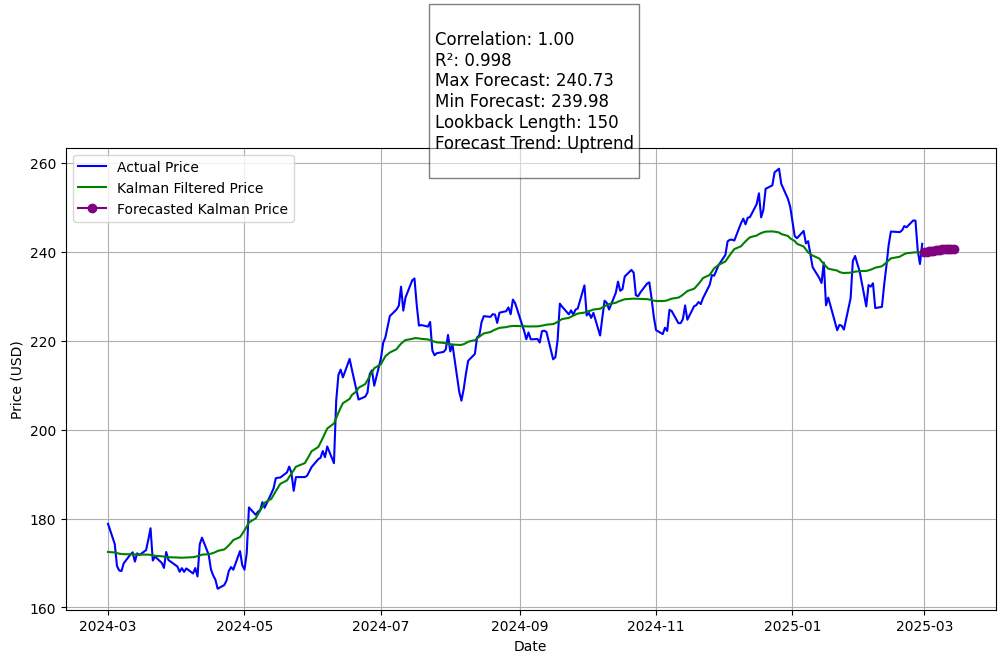

In [ ]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.ar_model import AutoReg
from pykalman import KalmanFilter

# ดึงข้อมูลราคาหุ้น AAPL
ticker = "AAPL"
df = yf.download(ticker, period="1y", interval="1d")

# เลือกเฉพาะคอลัมน์ 'Close'
df = df[['Close']]
df.dropna(inplace=True)

# ======= ขั้นตอน Kalman Filter =======
kf = KalmanFilter(
    transition_matrices=[1],
    observation_matrices=[1],
    initial_state_mean=df['Close'].iloc[0],
    initial_state_covariance=1,
    observation_covariance=1,
    transition_covariance=0.01
)

state_means, _ = kf.smooth(df['Close'].values)
df['Kalman_Filtered'] = state_means.flatten()
# ======================================

# กำหนด Lookback Length และ Forecast Days
LOOKBACK_LENGTH = 150
FORECAST_DAYS = 14

# Train โมเดลโดยใช้ Kalman Filtered Data
train_data = df['Kalman_Filtered'][-LOOKBACK_LENGTH:]
model = AutoReg(train_data, lags=5)
model_fit = model.fit()

# Forecast
forecast_values = model_fit.predict(start=len(train_data), end=len(train_data) + FORECAST_DAYS - 1)
forecast_dates = pd.date_range(df.index[-1], periods=FORECAST_DAYS+1, freq='D')[1:]

# สร้าง DataFrame สำหรับ Forecast
forecast_df = pd.DataFrame({'Date': forecast_dates, 'Forecast': forecast_values})
forecast_df.set_index('Date', inplace=True)

# ======= ฟังก์ชันวิเคราะห์แนวโน้ม =======
def detect_trend(forecast_values):
    # Check if forecast_values is empty
    if len(forecast_values) == 0:
        return "No trend data available"

    first = forecast_values.values[0] # Access the first element of the numpy array
    last = forecast_values.values[-1] # Access the last element of the numpy array

    if last > first and np.all(np.diff(forecast_values.values) > 0):
        return "Uptrend"
    elif last < first and np.all(np.diff(forecast_values.values) < 0):
        return "Downtrend"
    else:
        return "Sideways"
# วิเคราะห์แนวโน้มของช่วง Forecast
trend_result = detect_trend(forecast_values)
# ======================================

# คำนวณ Correlation และ R²
correlation = np.corrcoef(train_data[:-1], train_data[1:])[0, 1]
r2 = correlation ** 2

# ค่ามากสุดและน้อยสุดของ Forecast
max_forecast = forecast_values.max()
min_forecast = forecast_values.min()

# แสดงผล Model Statistics และแนวโน้ม
print(f"Correlation: {correlation:.2f}")
print(f"R²: {r2:.3f}")
print(f"Max Forecasted Value: {max_forecast:.2f}")
print(f"Min Forecasted Value: {min_forecast:.2f}")
print(f"Lookback Length: {LOOKBACK_LENGTH}")
print(f"Forecast Trend: {trend_result}")

# ======= Plot กราฟ =======
plt.figure(figsize=(12,6))

# Plot ราคาจริง
plt.plot(df.index, df['Close'], label='Actual Price', color='blue')

# Plot ราคาที่ผ่านการกรองด้วย Kalman Filter
plt.plot(df.index, df['Kalman_Filtered'], label='Kalman Filtered Price', color='green')

# Plot Forecast
plt.plot(forecast_df.index, forecast_df['Forecast'], label='Forecasted Kalman Price', color='purple', marker='o')
plt.plot(forecast_df.index, forecast_df['Forecast'], color='purple', linestyle='dashed')

# แสดง Model Statistics และแนวโน้มบนกราฟ
stats_text = f"""
Correlation: {correlation:.2f}
R²: {r2:.3f}
Max Forecast: {max_forecast:.2f}
Min Forecast: {min_forecast:.2f}
Lookback Length: {LOOKBACK_LENGTH}
Forecast Trend: {trend_result}
"""
plt.text(df.index[-LOOKBACK_LENGTH], df['Close'].max(), stats_text, fontsize=12, bbox=dict(facecolor='white', alpha=0.5))

# ตั้งค่ากราฟ
plt.xlabel("Date")
plt.ylabel("Price (USD)")
plt.legend()
plt.grid()
plt.show()

##Web app

In [ ]:
!pip install streamlit pykalman pyngrok

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.6/9.6 MB 77.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 248.5/248.5 kB 19.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 92.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 141.5/141.5 kB 12.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.1/79.1 kB 5.0 MB/s eta 0:00:00


In [ ]:
!ngrok authtoken 2tek6xLOwk2bZg9ZzDrUjVWVVh3_27tHWgMnYm3PqwzGqSLeL

Authtoken saved to configuration file: /root/.config/ngrok/ngrok.yml


In [ ]:
import streamlit as st
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.ar_model import AutoReg
from pykalman import KalmanFilter
from scipy.fftpack import fft
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
import tensorflow as tf
from sklearn.metrics import mean_squared_error
from pyngrok import ngrok
import os

In [ ]:
def apply_kalman_filter(data):
    kf = KalmanFilter(
        transition_matrices=[1],
        observation_matrices=[1],
        initial_state_mean=data.iloc[0],
        initial_state_covariance=1,
        observation_covariance=1,
        transition_covariance=0.01
    )
    state_means, _ = kf.smooth(data.values)
    return state_means.flatten()

def apply_autoreg(data, lookback=200, forecast_days=14):
    train_data = data[-lookback:]
    model = AutoReg(train_data, lags=5).fit()
    forecast_values = model.predict(start=len(train_data), end=len(train_data) + forecast_days - 1)
    return forecast_values

def build_lstm_model(input_shape):
    model = Sequential([
        LSTM(100, return_sequences=True, input_shape=input_shape),
        Dropout(0.3),
        LSTM(100, return_sequences=True),
        Dropout(0.3),
        LSTM(100),
        Dropout(0.3),
        Dense(1)
    ])
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001), loss='mean_squared_error')
    return model

def train_lstm(data, time_step=10, forecast_days=14):
    scaler = MinMaxScaler(feature_range=(0, 1))
    scaled_data = scaler.fit_transform(data.values.reshape(-1, 1))
    X, y = [], []
    for i in range(len(scaled_data) - time_step - 1):
        X.append(scaled_data[i:(i + time_step), 0])
        y.append(scaled_data[i + time_step, 0])
    X, y = np.array(X), np.array(y)
    X_train, X_test, y_train, y_test = X[:-forecast_days], X[-forecast_days:], y[:-forecast_days], y[-forecast_days:]
    X_train = X_train.reshape(X_train.shape[0], X_train.shape[1], 1)
    X_test = X_test.reshape(X_test.shape[0], X_test.shape[1], 1)
    model = build_lstm_model((X_train.shape[1], 1))
    model.fit(X_train, y_train, epochs=150, batch_size=32, verbose=0, validation_data=(X_test, y_test))
    predictions = model.predict(X_test)
    return scaler.inverse_transform(predictions)

st.title("Stock Price Prediction App")
uploaded_file = st.file_uploader("Upload CSV file", type=["csv"])
if uploaded_file:
    df = pd.read_csv(uploaded_file, skiprows=2,  parse_dates=True)
    df.columns = ["Date","Close", "High", "Low", "Open", "Volume"]
    df = df.astype({"Date":str,"Close": float, "High": float, "Low": float, "Open": float, "Volume": int})
    df['Date'] = pd.to_datetime(df['Date'])
    df["Kalman_Filtered"] = apply_kalman_filter(df["Close"])
    forecast_autoreg = apply_autoreg(df["Kalman_Filtered"])
    forecast_lstm = train_lstm(df["Kalman_Filtered"])
    st.line_chart(df["Close"])
    st.write("AutoReg Forecast:", forecast_autoreg)
    st.write("LSTM Predictions:", forecast_lstm)



2025-03-03 09:00:53.045 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-03-03 09:00:53.046 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-03-03 09:00:53.047 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-03-03 09:00:53.048 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-03-03 09:00:53.048 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-03-03 09:00:53.049 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-03-03 09:00:53.050 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


Streamlit app is live at: NgrokTunnel: "https://d391-34-142-255-165.ngrok-free.app" -> "http://localhost:8501"


In [ ]:
!ngrok ps


ngrok - tunnel local ports to public URLs and inspect traffic

USAGE:
  ngrok [command] [flags]

COMMANDS: 
  config          update or migrate ngrok's configuration file
  http            start an HTTP tunnel
  tcp             start a TCP tunnel
  tunnel          start a tunnel for use with a tunnel-group backend

EXAMPLES: 
  ngrok http 80                                                 # secure public URL for port 80 web server
  ngrok http --url baz.ngrok.dev 8080                           # port 8080 available at baz.ngrok.dev
  ngrok tcp 22                                                  # tunnel arbitrary TCP traffic to port 22
  ngrok http 80 --oauth=google --oauth-allow-email=foo@foo.com  # secure your app with oauth

Paid Features: 
  ngrok http 80 --url mydomain.com                              # run ngrok with your own custom domain
  ngrok http 80 --cidr-allow 2600:8c00::a03c:91ee:fe69:9695/32  # run ngrok with IP policy restrictions
  Upgrade your account at https://dash

In [ ]:
!pkill ngrok


In [ ]:
!gdown 1s0rrbZ6C_re697bqKZY7w0Fp8GW3fx0i

Downloading...
From (original): https://drive.google.com/uc?id=1s0rrbZ6C_re697bqKZY7w0Fp8GW3fx0i
From (redirected): https://drive.google.com/uc?id=1s0rrbZ6C_re697bqKZY7w0Fp8GW3fx0i&confirm=t&uuid=00cbe92d-87d3-4980-a813-b98baa46e28c
To: /content/app2.py
100% 6.86k/6.86k [00:00<00:00, 18.3MB/s]


In [ ]:
def start_ngrok():
    # Set the auth token (replace with your actual token)
    ngrok.set_auth_token("2tek6xLOwk2bZg9ZzDrUjVWVVh3_27tHWgMnYm3PqwzGqSLeL")

    # Open a tunnel to the Streamlit app (running on port 8501)
    url = ngrok.connect(8501)  # Explicitly specify port here
    print(f"Streamlit app is live at: {url}")

def main():
    os.system("streamlit run /content/app2.py &")
    start_ngrok()

if __name__ == "__main__":
    main()

Streamlit app is live at: NgrokTunnel: "https://e031-34-91-94-250.ngrok-free.app" -> "http://localhost:8501"


#Crypto

##Model 1

In [ ]:
!gdown 1udoE_m7rZYolBa98wsfsxUIWTq4X75Bc

Downloading...
From (original): https://drive.google.com/uc?id=1udoE_m7rZYolBa98wsfsxUIWTq4X75Bc
From (redirected): https://drive.google.com/uc?id=1udoE_m7rZYolBa98wsfsxUIWTq4X75Bc&confirm=t&uuid=f7c6eb6f-fcba-431b-985c-e92818ecfdae
To: /content/BTCUSD_1m_Binance.csv
100% 538M/538M [00:05<00:00, 99.4MB/s]


In [ ]:
!pip install pmdarima

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 22.9 MB/s eta 0:00:00


In [ ]:
!pip install --upgrade scikit-learn


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA

In [ ]:
data = pd.read_csv('/content/BTCUSD_1m_Binance.csv')
data['Open time'] = pd.to_datetime(data['Open time'])
data.set_index('Open time', inplace=True)

In [ ]:
data = data.loc[data.index >= "2025-01-01"]


In [ ]:
data = data.asfreq('min')  # 'T' represents minute-level frequency

prices = data['Close'].dropna()

In [ ]:
prices.index = prices.index.to_period('min')  # 'T' for minute-level frequency

In [ ]:
# Fit the ARIMA model
model = ARIMA(prices, order=(1,1,1))  # (p,d,q) values can be tuned
model_fit = model.fit()

/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/statespace/sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/statespace/sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'


<ipython-input-57-50b56d836050>:3: FutureWarning: 'T' is deprecated and will be removed in a future version, please use 'min' instead.
  future_index = pd.date_range(start=prices.index[-1], periods=10, freq='T')


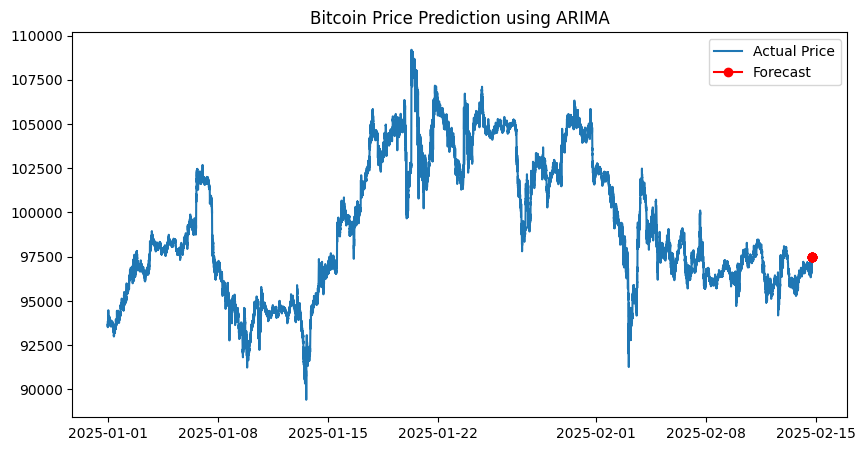

In [ ]:
future_forecast = model_fit.forecast(steps=10)  # Predict next 10 minutes
prices.index = prices.index.to_timestamp()
future_index = pd.date_range(start=prices.index[-1], periods=10, freq='T')

plt.figure(figsize=(10,5))
plt.plot(prices, label='Actual Price')
plt.plot(future_index, future_forecast, 'ro-', label='Forecast')
plt.legend()
plt.title('Bitcoin Price Prediction using ARIMA')
plt.show()

In [ ]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

# Split your data into train and test (you can adjust this split as needed)
train_size = int(len(prices) * 0.8)  # 80% for training, 20% for testing
train, test = prices[:train_size], prices[train_size:]

# Fit the ARIMA model on the training data
model = ARIMA(train, order=(1, 1, 1))
model_fit = model.fit()

# Make predictions on the test data
predictions = model_fit.forecast(steps=len(test))

# Normalize the metrics based on the range of the test data
range_test = test.max() - test.min()

# Calculate the evaluation metrics
mse = mean_squared_error(test, predictions) / range_test
mae = mean_absolute_error(test, predictions) / range_test
rmse = np.sqrt(mse)
r2 = r2_score(test, predictions)

# Print the normalized results
print(f'Normalized Mean Squared Error (MSE): {mse}')
print(f'Normalized Mean Absolute Error (MAE): {mae}')
print(f'Normalized Root Mean Squared Error (RMSE): {rmse}')
print(f'R-squared (R²): {r2}')


Normalized Mean Squared Error (MSE): 118.51067218360346
Normalized Mean Absolute Error (MAE): 0.11269322492631403
Normalized Root Mean Squared Error (RMSE): 10.886260707130042
R-squared (R²): -0.03991146114517807


##Model 2

/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/statespace/sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/statespace/sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'
<ipython-input-4-6c20ad296e15>:45: FutureWarning: 'T' is deprecated and will be removed in a future version, please use 'min' instead.
  future_index = pd.date_range(start=prices.index[-1], periods=future_steps+1, freq='T')[1:]


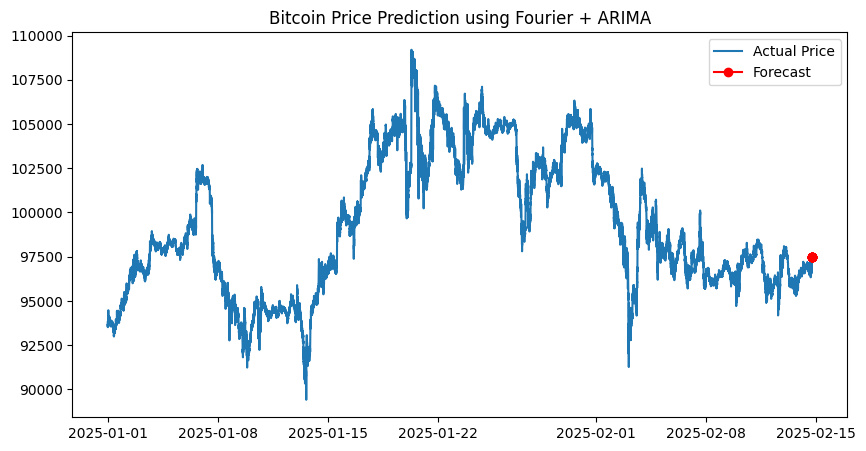

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA
from scipy.fftpack import fft, fftfreq

# โหลดข้อมูล
data = pd.read_csv('/content/BTCUSD_1m_Binance.csv')
data['Open time'] = pd.to_datetime(data['Open time'])
data.set_index('Open time', inplace=True)
data = data.loc[data.index >= "2025-01-01"]
data = data.asfreq('min')

# ดึงเฉพาะราคาปิด
prices = data['Close'].dropna()
prices.index = prices.index.to_period('min')

# 🔷 1. ทำ Fourier Transform
n = len(prices)
freqs = fftfreq(n, d=1)  # คำนวณความถี่
fft_values = fft(prices.to_numpy())  # ใช้ .to_numpy() เพื่อแปลงเป็น NumPy array

# 🔷 2. เลือกความถี่ที่สำคัญ
top_k = 5  # เลือกเฉพาะ 5 ความถี่ที่สำคัญ
idx = np.argsort(np.abs(fft_values))[-top_k:]  # หาค่าความถี่ที่เด่นที่สุด

# 🔷 3. สร้าง Fourier Features
t = np.arange(n)
fourier_terms = np.column_stack([np.sin(2 * np.pi * freqs[i] * t) for i in idx] +
                                [np.cos(2 * np.pi * freqs[i] * t) for i in idx])

# 🔷 4. ใช้ ARIMA กับ Fourier Features
prices.index = prices.index.to_timestamp()
model = ARIMA(prices, order=(1,1,1), exog=fourier_terms)
model_fit = model.fit()

# 🔷 5. ทำนายอนาคต
future_steps = 10
future_t = np.arange(n, n + future_steps)
future_fourier_terms = np.column_stack([np.sin(2 * np.pi * freqs[i] * future_t) for i in idx] +
                                       [np.cos(2 * np.pi * freqs[i] * future_t) for i in idx])
future_forecast = model_fit.forecast(steps=future_steps, exog=future_fourier_terms)

# 🔷 6. พล็อตผลลัพธ์
future_index = pd.date_range(start=prices.index[-1], periods=future_steps+1, freq='T')[1:]
plt.figure(figsize=(10,5))
plt.plot(prices, label='Actual Price')
plt.plot(future_index, future_forecast, 'ro-', label='Forecast')
plt.legend()
plt.title('Bitcoin Price Prediction using Fourier + ARIMA')
plt.show()


/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/statespace/sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/statespace/sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'
<ipython-input-12-150a3aa9ff3f>:45: FutureWarning: 'T' is deprecated and will be removed in a future version, please use 'min' instead.
  future_index = pd.date_range(start=prices.index[-1], periods=future_steps+1, freq='T')[1:]


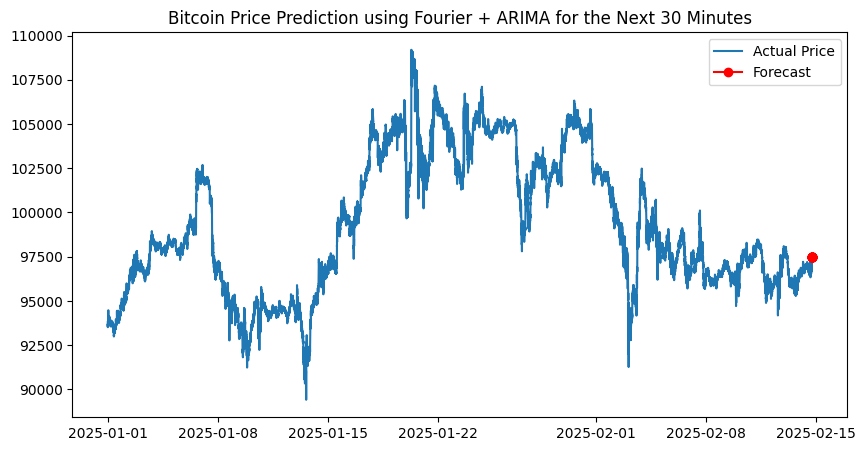

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA
from scipy.fftpack import fft, fftfreq

# โหลดข้อมูล
data = pd.read_csv('/content/BTCUSD_1m_Binance.csv')
data['Open time'] = pd.to_datetime(data['Open time'])
data.set_index('Open time', inplace=True)
data = data.loc[data.index >= "2025-01-01"]
data = data.asfreq('min')

# ดึงเฉพาะราคาปิด
prices = data['Close'].dropna()
prices.index = prices.index.to_period('min')

# 🔷 1. ทำ Fourier Transform
n = len(prices)
freqs = fftfreq(n, d=1)  # คำนวณความถี่
fft_values = fft(prices.to_numpy())  # ใช้ .to_numpy() เพื่อแปลงเป็น NumPy array

# 🔷 2. เลือกความถี่ที่สำคัญ
top_k = 5  # เลือกเฉพาะ 5 ความถี่ที่สำคัญ
idx = np.argsort(np.abs(fft_values))[-top_k:]  # หาค่าความถี่ที่เด่นที่สุด

# 🔷 3. สร้าง Fourier Features
t = np.arange(n)
fourier_terms = np.column_stack([np.sin(2 * np.pi * freqs[i] * t) for i in idx] +
                                [np.cos(2 * np.pi * freqs[i] * t) for i in idx])

# 🔷 4. ใช้ ARIMA กับ Fourier Features
prices.index = prices.index.to_timestamp()
model = ARIMA(prices, order=(1,1,1), exog=fourier_terms)
model_fit = model.fit()

# 🔷 5. ทำนายอนาคต (ปรับ future_steps เป็น 30)
future_steps = 30  # ทำนายสำหรับ 30 นาที
future_t = np.arange(n, n + future_steps)
future_fourier_terms = np.column_stack([np.sin(2 * np.pi * freqs[i] * future_t) for i in idx] +
                                       [np.cos(2 * np.pi * freqs[i] * future_t) for i in idx])
future_forecast = model_fit.forecast(steps=future_steps, exog=future_fourier_terms)

# 🔷 6. พล็อตผลลัพธ์
future_index = pd.date_range(start=prices.index[-1], periods=future_steps+1, freq='T')[1:]
plt.figure(figsize=(10, 5))
plt.plot(prices, label='Actual Price')
plt.plot(future_index, future_forecast, 'ro-', label='Forecast')
plt.legend()
plt.title('Bitcoin Price Prediction using Fourier + ARIMA for the Next 30 Minutes')
plt.show()
